In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from coords_workflow_utils import PreparedCoordsLoader
from data_registry import Bibliography
from pathlib import Path
import matplotlib.dates as mdates
import pandas as pd
from matplotlib.lines import Line2D
import os
import geopandas as gpd
import matplotlib.ticker as mticker
import os
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.cm import ScalarMappable


In [84]:
# test laufzeit ws300 von pangu laden
import gcsfs

fs = gcsfs.GCSFileSystem(token="anon")

ds_pangu = xr.open_zarr(
    "gs://weatherbench2/datasets/pangu/2018-2022_0012_0p25.zarr",
    consolidated=True,
    storage_options={"token": "anon"}
)
print('done')
pangu_msl = ds_pangu.wind_speed.sel(time=slice('2022-12-01', '2022-12-18'), latitude=slice(84,12), level=300).load()

done


## Verteilung Windevents

In [68]:

bib = Bibliography(Path("data"))
bib.add("energy", "WON", "daily", "subcountry", "prepared/WON_daily_subcountry_prepared_DJF.csv")

In [69]:
energy_entries = bib.get_by_category("energy")
energy_entry = energy_entries[0]
energy_name = energy_entry.name
energy_grid = energy_entry.grid
energy_timestep = energy_entry.timestep
energy_path = energy_entry.path
df_ene = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_path,
    energy_name=energy_name,
    region_ziel='Norddeutschland',
    quant=0.9,
    extreme_event='h',
)

In [70]:
print(df_ene)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [71]:
data = df_ene.values  # dein DataArray -> numpy array

# finde Wechsel (0->1 oder 1->0)
diff = np.diff(data)

# Start- und Endpunkte von 1-Sequenzen
starts = np.where(diff == 1)[0] + 1
ends = np.where(diff == -1)[0] + 1

# Sonderfälle (falls Serie mit 1 beginnt oder endet)
if data[0] == 1:
    starts = np.insert(starts, 0, 0)
if data[-1] == 1:
    ends = np.append(ends, len(data))

# Längen berechnen
lengths = ends - starts

In [72]:
unique_lengths, counts = np.unique(lengths, return_counts=True)

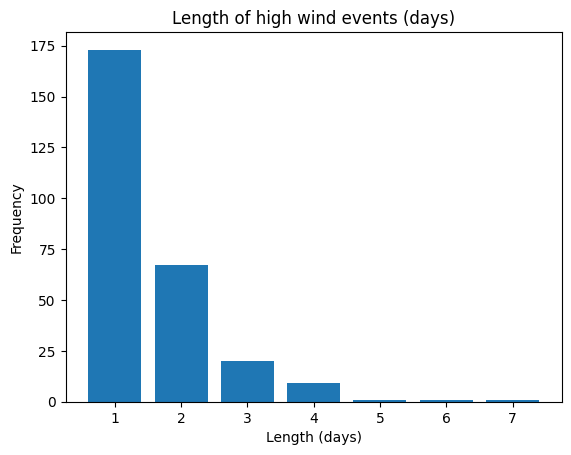

In [73]:
plt.bar(unique_lengths, counts)
plt.xlabel("Length (days)")
plt.ylabel("Frequency")
plt.title("Length of high wind events (days)")
plt.show()

In [81]:
# finde 5 tage event
target_length = 2

# Indizes der Events mit gewünschter Länge
idx = np.where(lengths == target_length)[0]

# Start- und Endzeiten dieser Events
event_starts = starts[idx]
event_ends = ends[idx]

# Zeitkoordinaten holen
times = df_ene.time.values

start_times = times[event_starts]
end_times = times[event_ends - 1]  # -1 weil end exklusiv ist

In [82]:
for s, e in zip(start_times, end_times):
    print(f"Event von {s} bis {e}")

Event von 1979-02-14T00:00:00.000000 bis 1979-02-15T00:00:00.000000
Event von 1980-12-13T00:00:00.000000 bis 1980-12-14T00:00:00.000000
Event von 1980-12-31T00:00:00.000000 bis 1981-01-01T00:00:00.000000
Event von 1981-01-14T00:00:00.000000 bis 1981-01-15T00:00:00.000000
Event von 1982-12-15T00:00:00.000000 bis 1982-12-16T00:00:00.000000
Event von 1982-12-20T00:00:00.000000 bis 1982-12-21T00:00:00.000000
Event von 1982-12-27T00:00:00.000000 bis 1982-12-28T00:00:00.000000
Event von 1984-01-16T00:00:00.000000 bis 1984-01-17T00:00:00.000000
Event von 1984-02-06T00:00:00.000000 bis 1984-02-07T00:00:00.000000
Event von 1985-02-01T00:00:00.000000 bis 1985-02-02T00:00:00.000000
Event von 1986-01-20T00:00:00.000000 bis 1986-01-21T00:00:00.000000
Event von 1986-01-31T00:00:00.000000 bis 1986-02-01T00:00:00.000000
Event von 1988-02-02T00:00:00.000000 bis 1988-02-03T00:00:00.000000
Event von 1989-01-14T00:00:00.000000 bis 1989-01-15T00:00:00.000000
Event von 1989-02-14T00:00:00.000000 bis 1989-02

In [76]:
# einzelne jahre plotten
da = df_ene.copy()

# Winterjahr: Dezember zählt zum nächsten Jahr
winter_year = xr.where(da['time.month'] == 12,
                       da['time.year'] + 1,
                       da['time.year'])

da = da.assign_coords(winter_year=("time", winter_year.values))

In [77]:
groups = list(da.groupby("winter_year"))

Text(0.5, 1.02, 'High wind events in winter months (DJF) for each winter year')

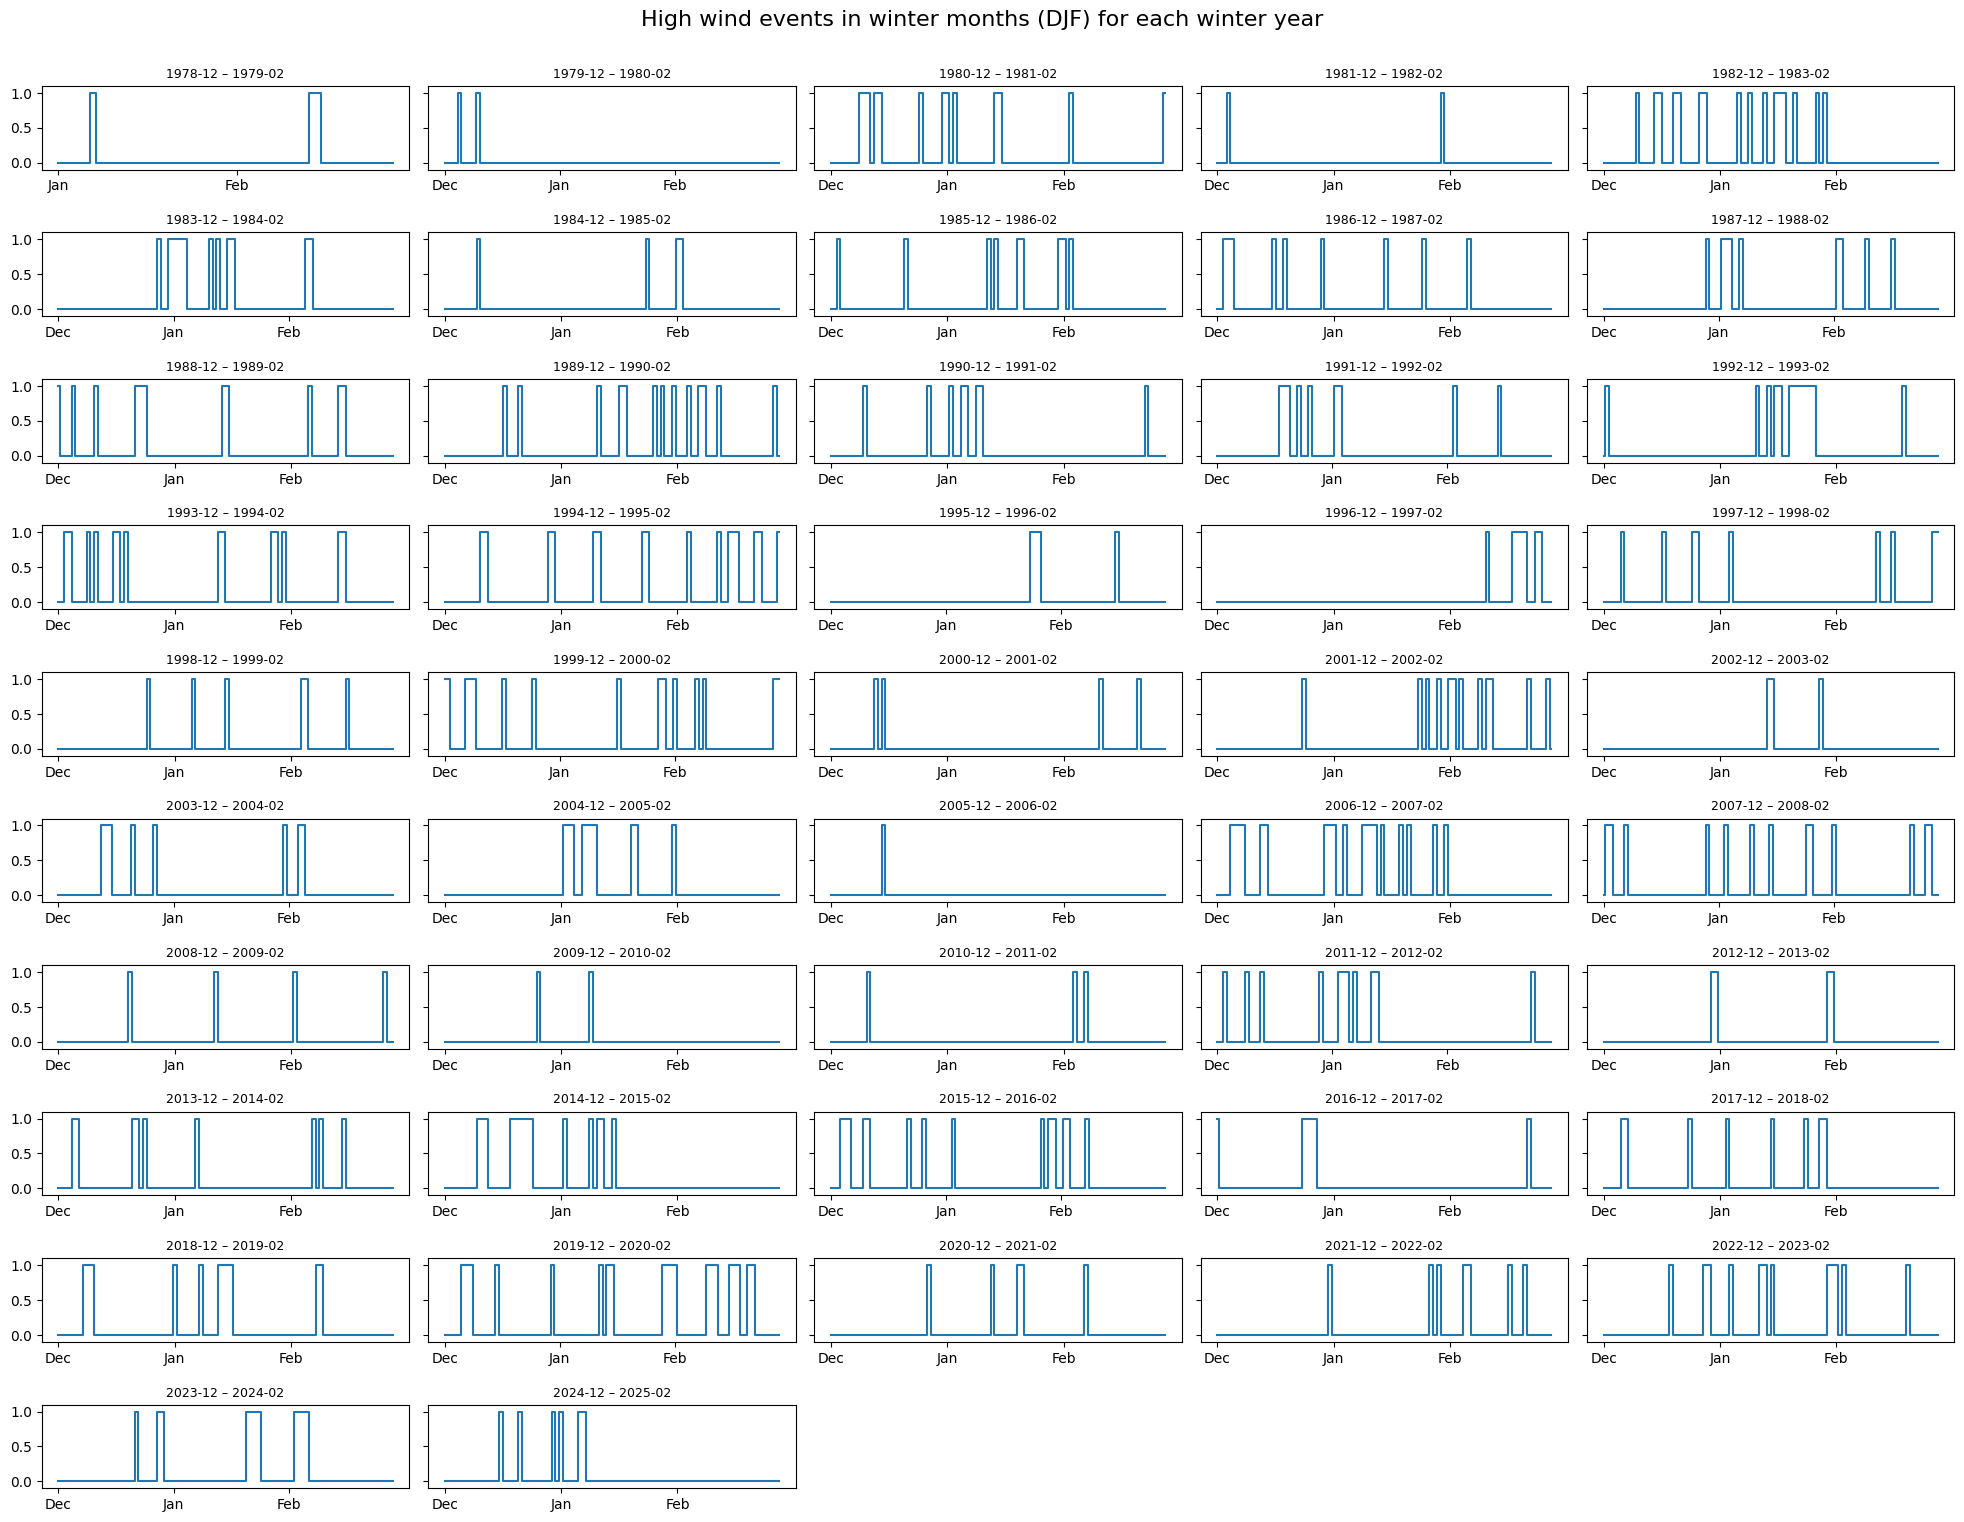

In [80]:
n = len(groups)
ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20,15), sharey=True)
axes = axes.flatten()

for ax, (wy, group) in zip(axes, groups):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[12, 1, 2]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    times = group.time.values
    values = group.values

    ax.plot(times, values, drawstyle="steps-mid")

    # Titel: "1990-12 – 1991-02"
    start_year = int(wy) - 1
    end_year = int(wy)
    ax.set_title(f"{start_year}-12 – {end_year}-02", fontsize=9)

    ax.set_ylim(-0.1, 1.1)

for ax in axes[len(groups):]:
    ax.axis("off")
plt.tight_layout(pad=2.0, h_pad=1.5, w_pad=1.0)
plt.suptitle("High wind events in winter months (DJF) for each winter year", fontsize=16, y=1.02)

In [79]:
stop here

SyntaxError: invalid syntax (4067800170.py, line 1)

## Testplots ERA5

In [ ]:
df = xr.open_dataset("data/domino_output_coords_weatherbench/WON/WON-l_Norddeutschland_Z500-MSL_EUROPE_1979_lags_-6_-3_0_composites_coords_deseasonalized_DJF.nc")

In [ ]:
df = xr.open_dataset('data/ERA5/mean_sea_level_pressure/era5_daily_weatherbench2_mean_sea_level_pressure_1985.nc')

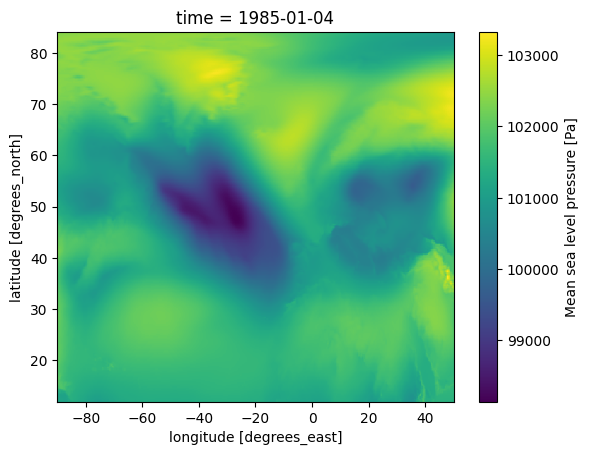

In [ ]:
df = df.assign_coords(
    longitude=(((df.longitude + 180) % 360) - 180)
)

df = df.sortby("longitude")
df['mean_sea_level_pressure'].isel(time=3).plot()

In [ ]:
df.geopotential

<xarray.DataArray 'geopotential' (lag: 3, index_val: 2, latitude: 289,
                                  longitude: 561)> Size: 4MB
[972774 values with dtype=float32]
Coordinates:
  * lag        (lag) int64 24B -6 -3 0
  * index_val  (index_val) int64 16B 0 1
  * latitude   (latitude) float32 1kB 84.0 83.75 83.5 83.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 2kB 270.0 270.2 270.5 ... 49.5 49.75 50.0
Attributes:
    long_name:       Geopotential
    short_name:      z
    standard_name:   geopotential
    units:           m**2 s**-2
    is_categorical:  0

In [ ]:
print(df.level)

AttributeError: 'Dataset' object has no attribute 'level'

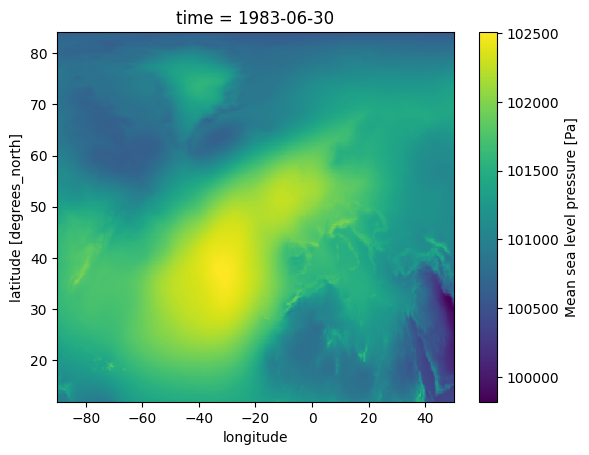

In [ ]:
df = df.assign_coords(
    longitude=(((df.longitude + 180) % 360) - 180)
)

df = df.sortby("longitude")
df_sorted = df.sortby("latitude")

df_sorted['mean_sea_level_pressure'][29, :, :].plot()

In [ ]:
df = xr.open_dataset("C:/Users/peter/Desktop/UNI/Masterarbeit/program_copy/data/ERA5/mean_sea_level_pressure/era5_daily_weatherbench2_mean_sea_level_pressure_1983.nc")

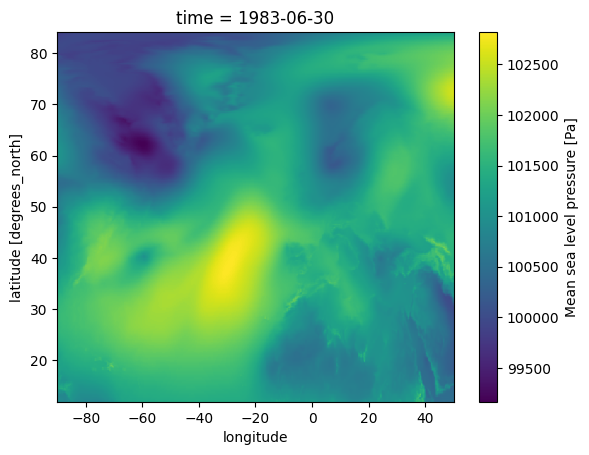

In [ ]:
df = df.assign_coords(
    longitude=(((df.longitude + 180) % 360) - 180)
)

df = df.sortby("longitude")
df_sorted = df.sortby("latitude")

df_sorted['mean_sea_level_pressure'][180, :, :].plot()

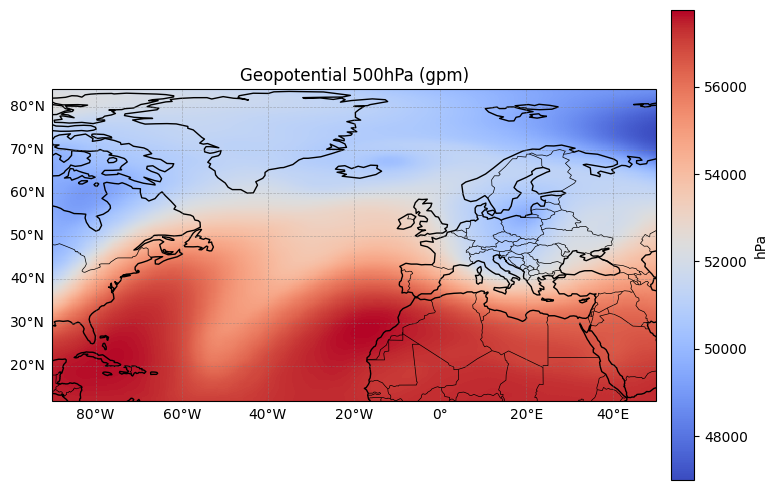

In [ ]:
data =df_sorted['geopotential'][1, :, :]# df['geopotential'][1,:,:]
# -----------------------------
fig, ax = plt.subplots(
    figsize=(8, 5),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# gemeinsame Farbskala (optional anpassen)
vmin = float(data.min())
vmax = float(data.max())

# -----------------------------
# PLOT
# -----------------------------
im = data.plot.pcolormesh(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# -----------------------------
# MAP FEATURES
# -----------------------------
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)

# Nur links & unten Labels anzeigen (üblich für Karten)
gl.top_labels = False
gl.right_labels = False

# Optional: schöner formatieren
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}
# Europa-Ausschnitt
# ax.set_extent([-10, 45, 27, 72])

# Titel
ax.set_title("Geopotential 500hPa (gpm)")

# -----------------------------
# COLORBAR
# -----------------------------
cbar = plt.colorbar(im, ax=ax, orientation="vertical", pad=0.02)
cbar.set_label("hPa")

# -----------------------------
# SHOW
# -----------------------------
plt.tight_layout()
plt.show()

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# -----------------------------
# DATASET LADEN
# -----------------------------
ds = df

# Variable auswählen (z.B. MSL)
var = ds["mean_sea_level_pressure"]/100

lags = var.lag.values
indices = var.index_val.values

# -----------------------------
# FIGURE SETUP
# -----------------------------
nrows = len(lags)
ncols = len(indices)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(4*ncols, 3*nrows),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Falls nur 1 Dimension → axes anpassen
if nrows == 1:
    axes = axes[np.newaxis, :]
if ncols == 1:
    axes = axes[:, np.newaxis]

# -----------------------------
# GEMEINSAME COLOR SCALE
# -----------------------------
vmin = var.min().values
vmax = var.max().values

# -----------------------------
# LOOP
# -----------------------------
for i, lag in enumerate(lags):
    for j, idx in enumerate(indices):
        ax = axes[i, j]

        data = var.sel(lag=lag, index_val=idx)

        im = data.plot.pcolormesh(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            add_colorbar=False
        )

        # Europakarte
        ax.coastlines()
        ax.add_feature(cfeature.BORDERS, linewidth=0.5)

        ax.set_title(f"Lag={lag}, Index={idx}")

# -----------------------------
# GEMEINSAME COLORBAR
# -----------------------------
fig.subplots_adjust(right=0.88)

# Eigene Achse für Colorbar
cbar_ax = fig.add_axes([0.9, 0.15, 0.02, 0.7])

cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("mean sea level pressure [hPa]")
#plt.tight_layout()
plt.show()

KeyError: "No variable named 'mean_sea_level_pressure'. Variables on the dataset include ['latitude', 'level', 'time', 'geopotential', 'longitude']"

## Plotte Wetterlage an False Positive Tagen

In [35]:
df = xr.open_dataset('data/ERA5/ERA5-2017-01-04.nc')
print(df)

<xarray.Dataset> Size: 47MB
Dimensions:     (valid_time: 24, latitude: 289, longitude: 561)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 192B 2017-01-04 ... 2017-01-04T23...
    expver      (valid_time) <U4 384B ...
  * latitude    (latitude) float64 2kB 84.0 83.75 83.5 83.25 ... 12.5 12.25 12.0
  * longitude   (longitude) float64 4kB -90.0 -89.75 -89.5 ... 49.5 49.75 50.0
    number      int64 8B ...
Data variables:
    msl         (valid_time, latitude, longitude) float32 16MB ...
    u100        (valid_time, latitude, longitude) float32 16MB ...
    v100        (valid_time, latitude, longitude) float32 16MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-07-09T09:18 GRIB to CDM+CF via cfgrib-0.9.1...


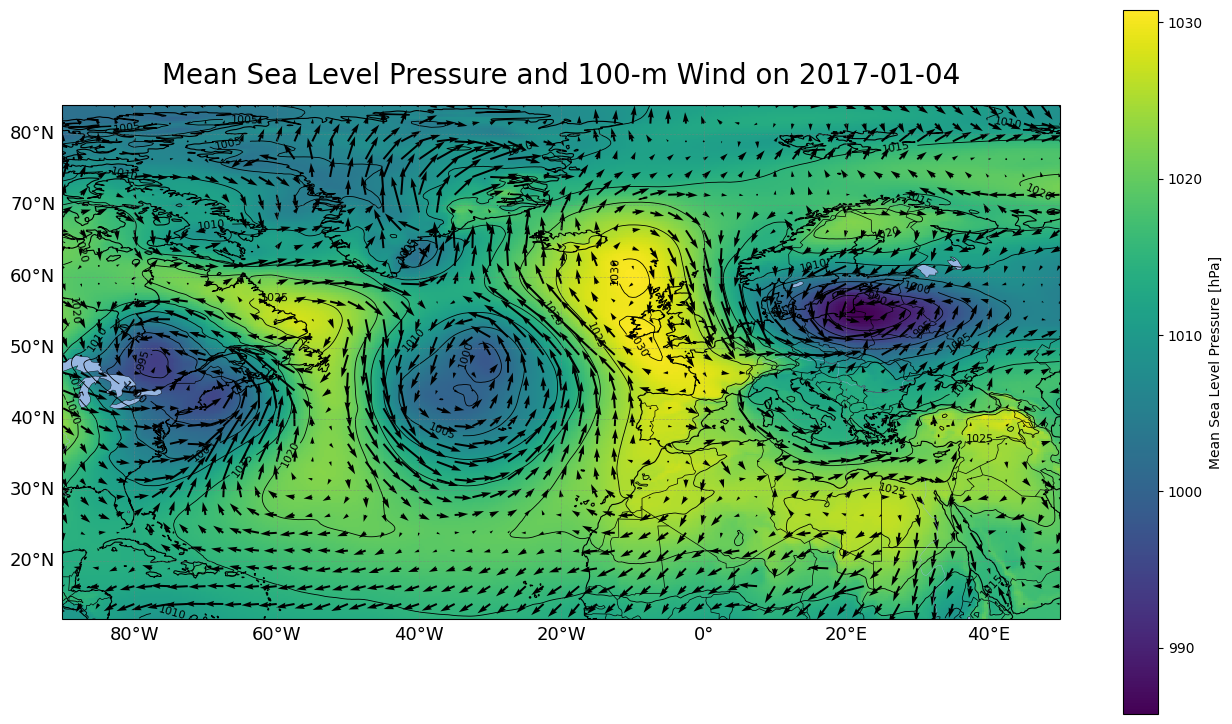

In [36]:
# Mittel über die 24 Stunden
ds_day = df.mean(dim="valid_time")

# ---------------------------------------------------------
# Windgeschwindigkeit und Windrichtung berechnen
# ---------------------------------------------------------
u = ds_day["u100"]
v = ds_day["v100"]
msl = ds_day["msl"]

# Windgeschwindigkeit (m/s)
wind_speed = np.sqrt(u**2 + v**2)

# Meteorologische Windrichtung (0° = Norden, 90° = Osten)
wind_dir = (270 - np.degrees(np.arctan2(v, u))) % 360

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax = plt.axes(projection=ccrs.PlateCarree())

# Kartenelemente
ax.coastlines(resolution="50m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="white")
ax.add_feature(cfeature.LAKES, edgecolor="black", linewidth=0.3)
ax.add_feature(cfeature.RIVERS, linewidth=0.3)

# ---------------------------------------------------------
# MSL als Farbkarte
# Falls in Pa -> in hPa umrechnen
# ---------------------------------------------------------
msl_hpa = msl / 100.0

pcm = ax.pcolormesh(
    ds_day.longitude,
    ds_day.latitude,
    msl_hpa,
    cmap="viridis",
    shading="auto",
    transform=ccrs.PlateCarree(),
)

cbar = plt.colorbar(pcm, ax=ax, shrink=0.8)
cbar.set_label("Mean Sea Level Pressure [hPa]")

# Optional: Isobaren
cs = ax.contour(
    ds_day.longitude,
    ds_day.latitude,
    msl_hpa,
    levels=np.arange(np.floor(msl_hpa.min()/5)*5,
                     np.ceil(msl_hpa.max()/5)*5 + 1,
                     5),
    colors="k",
    linewidths=0.6,
    transform=ccrs.PlateCarree(),
)
ax.clabel(cs, inline=True, fontsize=8)

# ---------------------------------------------------------
# Windpfeile
# (ausdünnen, damit der Plot lesbar bleibt)
# ---------------------------------------------------------
skip = 10

ax.quiver(
    ds_day.longitude.values[::skip],
    ds_day.latitude.values[::skip],
    u.values[::skip, ::skip],
    v.values[::skip, ::skip],
    transform=ccrs.PlateCarree(),
    scale=500,
    width=0.002,
    color="black",
)

ax.set_title("Mean Sea Level Pressure and 100-m Wind on 2017-01-04", fontsize=20,
    pad=15,
)

gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 13}
gl.ylabel_style = {"size": 13}
plt.tight_layout(rect=[0.05, 0.05, 1, 0.96])

plt.savefig("fig/quickplots/WON/l/FP-mean_sea_level_pressure_and_wind_2017-01-04.png", dpi=300, bbox_inches="tight")
plt.show()

## TSO Zonen und Tabellen

In [30]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Dateien einlesen
# --------------------------------------------------

shapefile = "data/NUTS_RG_20M_2024_3035.shp"
csv_file = "data/Energieversorger_NUTS.csv"

nuts = gpd.read_file(shapefile)
netz = pd.read_csv(csv_file, sep=";")


In [31]:

# --------------------------------------------------
# 3. CSV mit Geodaten verbinden
# --------------------------------------------------

nuts_de = nuts.merge(
    netz,
    left_on="NUTS_ID",
    right_on="NUTS-2",
    how="left"
)

In [32]:
nuts_nde = ['DEF0', 'DE60', 'DE80', 'DE93', 'DE94', 'DE50']

In [33]:
nuts_de = nuts_de[
    (nuts_de["CNTR_CODE"] == "DE")
].copy()

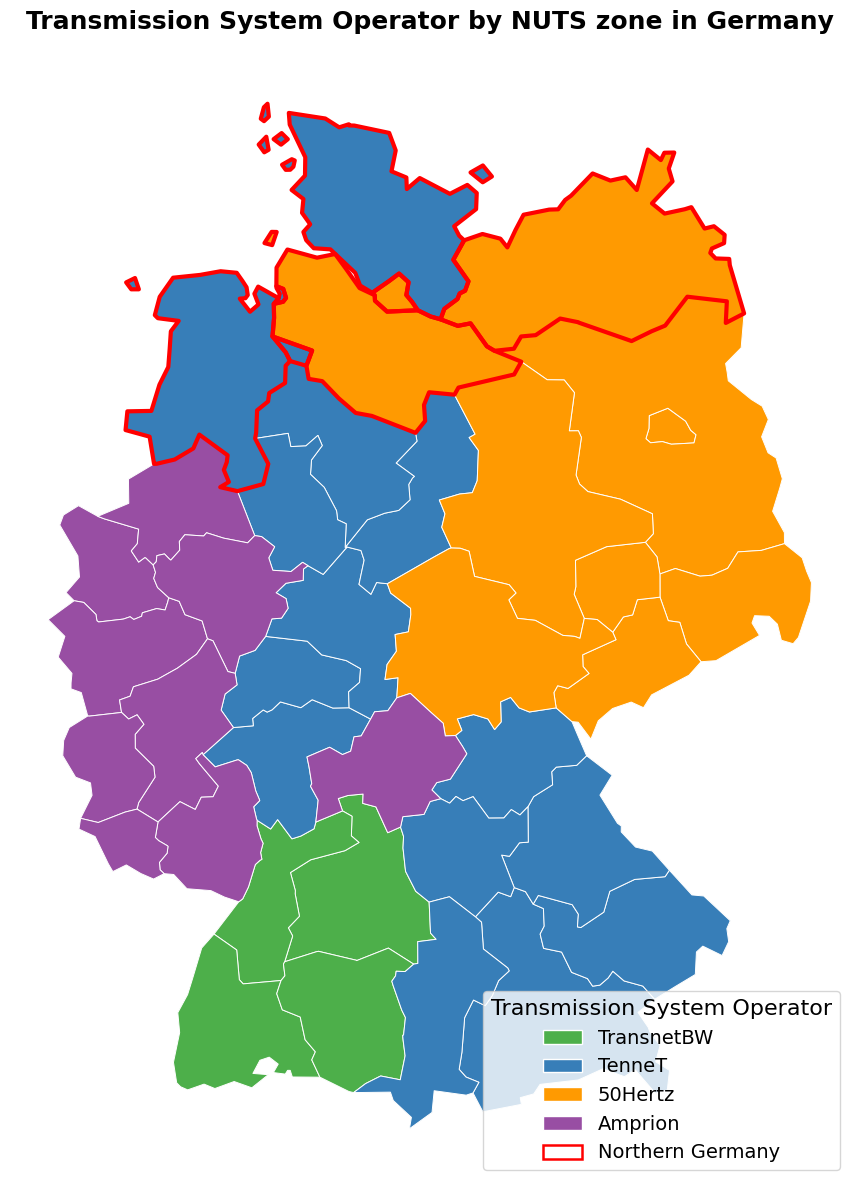

In [37]:

from matplotlib.patches import Patch
# --------------------------------------------------
# 4. Karte zeichnen
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 12))

# Nicht zugeordnete NUTS-Gebiete
nuts_de[nuts_de["Dominant TSO"].isna()].plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.5
)

# Netzbetreiber
farben = {
    "TransnetBW": "#4DAF4A",
    "TenneT": "#377EB8",
    "50Hertz": "#FF9A01",
    "Amprion": "#984EA3",
}

for betreiber, farbe in farben.items():
    nuts_de[nuts_de["Dominant TSO"] == betreiber].plot(
        ax=ax,
        color=farbe,
        edgecolor="white",
        linewidth=0.7,
        label=betreiber
    )

nuts_de[nuts_de["NUTS_ID"].isin(nuts_nde)].plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=3,
    zorder=5
)

# --------------------------------------------------
# 5. Darstellung
# --------------------------------------------------

ax.set_title(
    "Transmission System Operator by NUTS zone in Germany",
    fontweight="bold",
    fontsize=18
)

legend_elements = [
    Patch(
        facecolor=farbe,
        edgecolor="white",
        label=betreiber
    )
    for betreiber, farbe in farben.items()
]
# Zusätzlicher Legendeneintrag für die rot umrandeten NUTS-Zonen
legend_elements.append(
    Patch(
        facecolor="none",
        edgecolor="red",
        linewidth=1.8,
        label="Northern Germany"
    )
)
ax.legend(
    handles=legend_elements,
    title="Transmission System Operator",
    loc="lower right",
    frameon=True,
    fontsize=14,
    title_fontsize=16
)

ax.set_axis_off()

plt.tight_layout()
plt.savefig("fig/network_operators_germany_mitNorddeutschland.png")
plt.show()

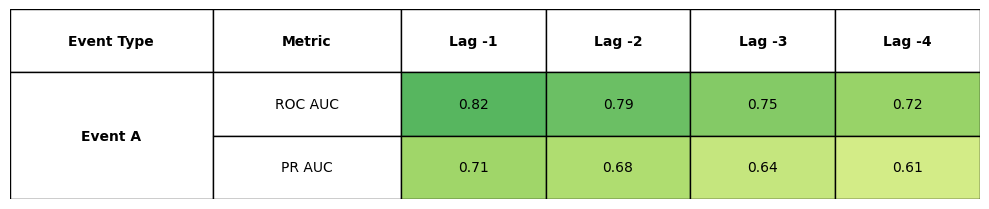

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

df = pd.DataFrame(
    {
        "Lag -1": [0.82, 0.71],
        "Lag -2": [0.79, 0.68],
        "Lag -3": [0.75, 0.64],
        "Lag -4": [0.72, 0.61],
    },
    index=["ROC AUC", "PR AUC"]
)

event_type = "Event A"

# -----------------------------
# Einstellungen
# -----------------------------

norm = Normalize(vmin=0, vmax=1)
cmap = plt.cm.RdYlGn

n_lags = len(df.columns)

# Spaltenbreiten
event_width = 1.4
metric_width = 1.3
lag_width = 1.0

total_width = event_width + metric_width + n_lags * lag_width

# -----------------------------
# Plot
# -----------------------------

fig, ax = plt.subplots(figsize=(10, 2.2))

ax.set_xlim(0, total_width)
ax.set_ylim(0, 3)
ax.axis("off")

# -----------------------------
# Header
# -----------------------------

headers = ["Event Type", "Metric"] + list(df.columns)
widths = [event_width, metric_width] + [lag_width] * n_lags

x = 0

for header, width in zip(headers, widths):

    rect = Rectangle(
        (x, 2),
        width,
        1,
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )

    ax.add_patch(rect)

    ax.text(
        x + width / 2,
        2.5,
        header,
        ha="center",
        va="center",
        fontweight="bold"
    )

    x += width


# -----------------------------
# Event Type
# über beide Zeilen
# -----------------------------

rect = Rectangle(
    (0, 0),
    event_width,
    2,
    facecolor="white",
    edgecolor="black",
    linewidth=1
)

ax.add_patch(rect)

ax.text(
    event_width / 2,
    1,
    event_type,
    ha="center",
    va="center",
    fontweight="bold"
)


# -----------------------------
# ROC AUC / PR AUC
# -----------------------------

for i, metric in enumerate(df.index):

    # y-Position
    y = 1 - i

    # Metric-Spalte
    rect = Rectangle(
        (event_width, y),
        metric_width,
        1,
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )

    ax.add_patch(rect)

    ax.text(
        event_width + metric_width / 2,
        y + 0.5,
        metric,
        ha="center",
        va="center"
    )

    # Werte
    for j, col in enumerate(df.columns):

        value = df.loc[metric, col]

        x = event_width + metric_width + j * lag_width

        rect = Rectangle(
            (x, y),
            lag_width,
            1,
            facecolor=cmap(norm(value)),
            edgecolor="black",
            linewidth=1
        )

        ax.add_patch(rect)

        ax.text(
            x + lag_width / 2,
            y + 0.5,
            f"{value:.2f}",
            ha="center",
            va="center"
        )


plt.tight_layout()
plt.show()

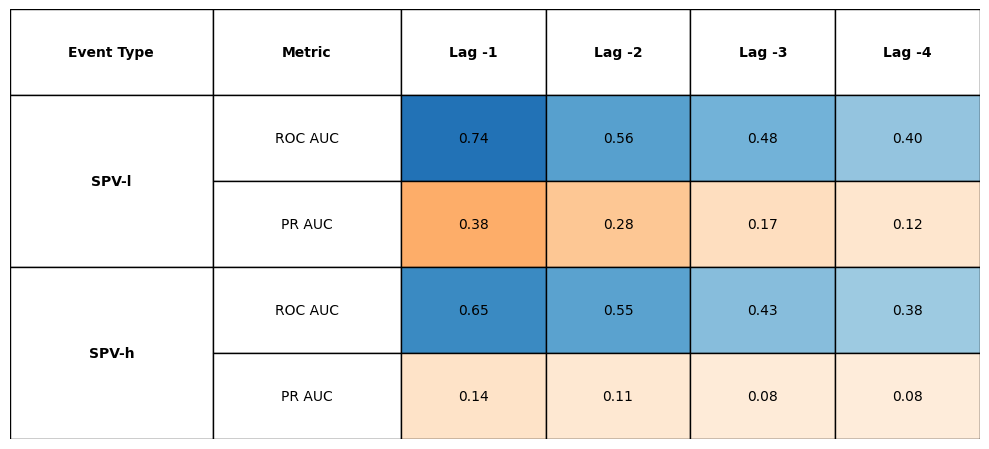

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle


# ============================================================
# DATEN
# ============================================================

data = {
    # "WON-l": pd.DataFrame(
    #     {
    #         "Lag -1": [0.599, 0.130],
    #         "Lag -2": [0.581, 0.121],
    #         "Lag -3": [0.584, 0.121],
    #         "Lag -4": [0.589, 0.121],
    #     },
    #     index=["ROC AUC", "PR AUC"]
    # ),

    # "WON-h": pd.DataFrame(
    #     {
    #         "Lag -1": [0.590, 0.123],
    #         "Lag -2": [0.473, 0.055],
    #         "Lag -3": [0.426, 0.050],
    #         "Lag -4": [0.440, 0.054],
    #     },
    #     index=["ROC AUC", "PR AUC"]
    # )#,

    "SPV-l": pd.DataFrame(
        {
            "Lag -1": [0.745, 0.381],
            "Lag -2": [0.560, 0.282],
            "Lag -3": [0.483, 0.169],
            "Lag -4": [0.400, 0.125],
        },
        index=["ROC AUC", "PR AUC"]
    ),

    "SPV-h": pd.DataFrame(
            {
                "Lag -1": [0.654, 0.143],
                "Lag -2": [0.554, 0.108],
                "Lag -3": [0.430, 0.084],
                "Lag -4": [0.378, 0.077],
            },
            index=["ROC AUC", "PR AUC"]
        )
}

# ============================================================
# FARBESKALEN
# ============================================================

# Beide Skalen gehen von 0 bis 1
norm_roc = Normalize(vmin=0, vmax=1)
norm_pr = Normalize(vmin=0, vmax=1)

# Unterschiedliche Colormaps
cmap_roc = plt.cm.Blues
cmap_pr = plt.cm.Oranges


# ============================================================
# TABELLEN-EINSTELLUNGEN
# ============================================================

n_lags = 4
n_events = len(data)

event_width = 1.4
metric_width = 1.3
lag_width = 1.0

total_width = (
    event_width
    + metric_width
    + n_lags * lag_width
)

# 1 Headerzeile + 2 Zeilen pro Event
total_height = 1 + n_events * 2


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 2 + n_events * 1.3)
)

ax.set_xlim(0, total_width)
ax.set_ylim(0, total_height)

ax.axis("off")


# ============================================================
# HEADER
# ============================================================

headers = [
    "Event Type",
    "Metric",
    "Lag -1",
    "Lag -2",
    "Lag -3",
    "Lag -4"
]

widths = [
    event_width,
    metric_width,
    lag_width,
    lag_width,
    lag_width,
    lag_width
]

x = 0

for header, width in zip(headers, widths):

    rect = Rectangle(
        (x, total_height - 1),
        width,
        1,
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )

    ax.add_patch(rect)

    ax.text(
        x + width / 2,
        total_height - 0.5,
        header,
        ha="center",
        va="center",
        fontweight="bold"
    )

    x += width


# ============================================================
# EVENT TYPES
# ============================================================

current_top = total_height - 1


for event_type, df in data.items():

    # --------------------------------------------------------
    # EVENT TYPE ZELLE
    # Eine Zelle über ROC AUC + PR AUC
    # --------------------------------------------------------

    y_event = current_top - 2

    rect = Rectangle(
        (0, y_event),
        event_width,
        2,
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )

    ax.add_patch(rect)

    ax.text(
        event_width / 2,
        y_event + 1,
        event_type,
        ha="center",
        va="center",
        fontweight="bold"
    )


    # --------------------------------------------------------
    # ROC AUC / PR AUC
    # --------------------------------------------------------

    for i, metric in enumerate(df.index):

        y = current_top - i - 1


        # ----------------------------------------------------
        # METRIC-SPALTE
        # ----------------------------------------------------

        rect = Rectangle(
            (event_width, y),
            metric_width,
            1,
            facecolor="white",
            edgecolor="black",
            linewidth=1
        )

        ax.add_patch(rect)

        ax.text(
            event_width + metric_width / 2,
            y + 0.5,
            metric,
            ha="center",
            va="center"
        )


        # ----------------------------------------------------
        # WERTE
        # ----------------------------------------------------

        for j, col in enumerate(df.columns):

            value = df.loc[metric, col]

            x = (
                event_width
                + metric_width
                + j * lag_width
            )


            # -----------------------------------------------
            # Unterschiedliche Farbskala
            # -----------------------------------------------

            if metric == "ROC AUC":

                facecolor = cmap_roc(
                    norm_roc(value)
                )

            elif metric == "PR AUC":

                facecolor = cmap_pr(
                    norm_pr(value)
                )

            else:

                facecolor = "white"


            # -----------------------------------------------
            # Zelle
            # -----------------------------------------------

            rect = Rectangle(
                (x, y),
                lag_width,
                1,
                facecolor=facecolor,
                edgecolor="black",
                linewidth=1
            )

            ax.add_patch(rect)


            # -----------------------------------------------
            # Wert
            # -----------------------------------------------

            ax.text(
                x + lag_width / 2,
                y + 0.5,
                f"{value:.2f}",
                ha="center",
                va="center"
            )


    # --------------------------------------------------------
    # Nächster Event Type
    # --------------------------------------------------------

    current_top -= 2


# ============================================================
# PLOT
# ============================================================

plt.tight_layout()
plt.savefig("fig/pangu_predictability/ROC-PR_model-lags_predictability-pangu_2021-2022.png")
plt.show()

## Ereignistage für TSO überprüfen

In [71]:
# events laden für die einzelnen tso zonen
bib = Bibliography(Path("data"))
bib.add("energy", "WON", "daily", "subcountry", "prepared/WON_daily_subcountry_prepared_DJF.csv")
# bib.add("energy", "SPV", "daily", "subcountry", "prepared/SPV_daily_subcountry_prepared_DJF.csv")
# erstelldatum = dt.date.today()
lags = [-4,-3,-2,-1,0] # [-6, -5, -4, -3, -2, -1, 0]
region_prec = "EUROPE"  # welche Daten werden als precursor verwendet
timeperiod = "1979-2025"  # zeitraum der analysierten daten
quant = 0.9  # welches quantile => def extreme event
extreme_event = "h"  # l=low 0.1, h=high 0.9

energy_entries = bib.get_by_category("energy")
energy_entry = energy_entries[0]

In [72]:
region_ziel = "50Hertz"

event_50Hertz = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event_50Hertz)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [73]:
region_ziel = "Amprion"

event_Amprion = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event_Amprion)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [74]:
region_ziel = "TransnetBW"

event_TransnetBW = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event_TransnetBW)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [75]:
region_ziel = "TenneT"

event_TenneT = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event_TenneT)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


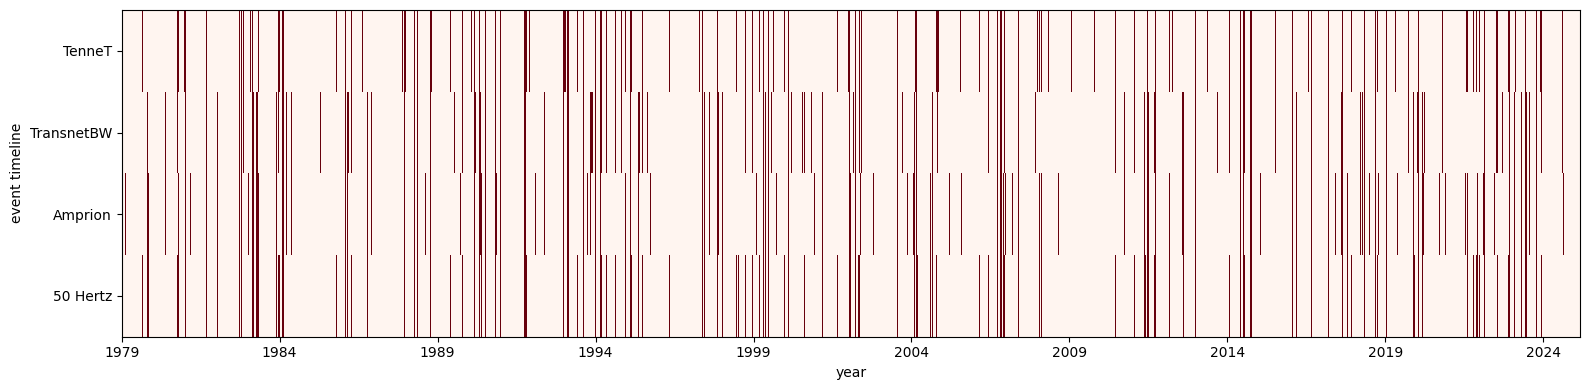

In [76]:
series = {
    "50 Hertz": event_50Hertz,
    "Amprion": event_Amprion,
    "TransnetBW": event_TransnetBW,
    "TenneT": event_TenneT,
}

# DataFrame aus den 4 Zeitreihen
df = pd.DataFrame({
    name: da.values
    for name, da in series.items()
}, index=pd.to_datetime(event_50Hertz.time.values))

# Plot
fig, ax = plt.subplots(figsize=(16, 4))

ax.imshow(
    df.T,
    cmap="Reds",
    aspect="auto",
    interpolation="none",
    extent=[
        df.index[0].toordinal(),
        df.index[-1].toordinal(),
        -0.5,
        len(df.columns) - 0.5
    ]
)

ax.set_yticks(range(len(df.columns)))
ax.set_yticklabels(df.columns)

# Datumsachse
ax.set_xlim(
    df.index[0].toordinal(),
    df.index[-1].toordinal()
)

years = pd.date_range(
    df.index.min(),
    df.index.max(),
    freq="5YS"
)

ax.set_xticks(years.map(pd.Timestamp.toordinal))
ax.set_xticklabels(years.year)

ax.set_xlabel("year")
ax.set_ylabel("event timeline")

plt.tight_layout()
plt.savefig(f'fig/event_timeline_TSO_{energy_entry.name}-{extreme_event}.png')
plt.show()

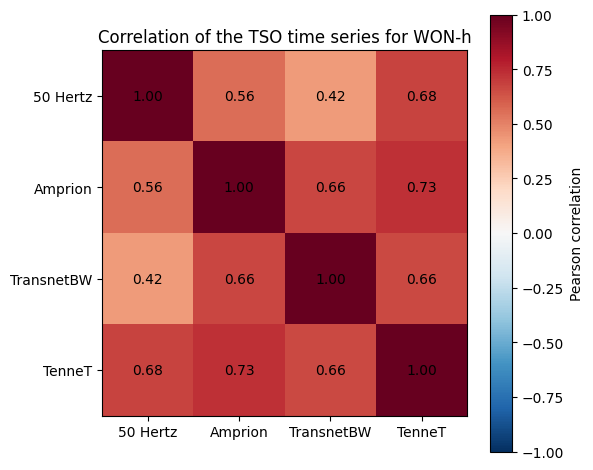

In [77]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1,
    cmap="RdBu_r"
)

# Achsenbeschriftungen
ax.set_xticks(np.arange(len(corr.columns)))
ax.set_yticks(np.arange(len(corr.columns)))

ax.set_xticklabels(corr.columns)
ax.set_yticklabels(corr.columns)

# Korrelationswerte in die Felder schreiben
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Pearson correlation")

ax.set_title(f"Correlation of the TSO time series for {energy_entry.name}-{extreme_event}")

plt.tight_layout()
plt.savefig(f'fig/TSO_{energy_entry.name}-{extreme_event}_correlation.png')
plt.show()

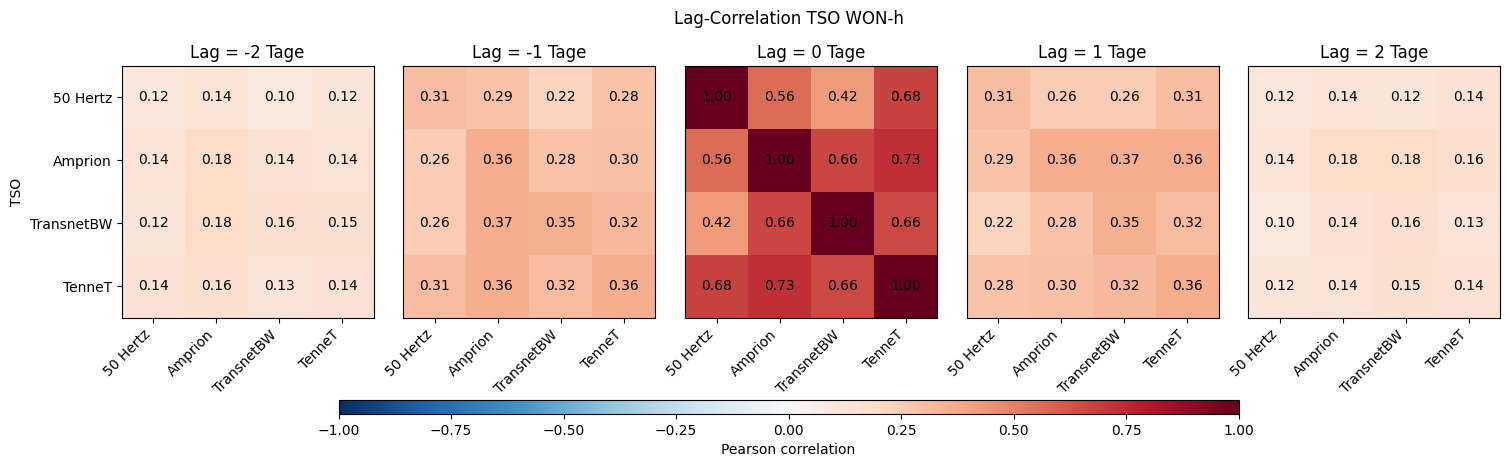

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

lags = [-2, -1, 0, 1, 2]

# Lag-Korrelationen berechnen
corr_matrices = {}

for lag in lags:
    corr = pd.DataFrame(
        index=df.columns,
        columns=df.columns,
        dtype=float
    )

    for source in df.columns:
        for target in df.columns:
            corr.loc[source, target] = (
                df[source].shift(lag).corr(df[target])
            )

    corr_matrices[lag] = corr


# Abbildung
fig, axes = plt.subplots(
    1, 5,
    figsize=(18, 4),
    sharey=True
)

vmin = -1
vmax = 1

for k, (ax, lag) in enumerate(zip(axes, lags)):

    corr = corr_matrices[lag]

    im = ax.imshow(
        corr.values,
        vmin=vmin,
        vmax=vmax,
        cmap="RdBu_r"
    )

    # X-Achse
    ax.set_xticks(np.arange(len(df.columns)))
    ax.set_xticklabels(
        df.columns,
        rotation=45,
        ha="right"
    )

    # Y-Achse nur beim ersten Plot
    if k == 0:
        ax.set_yticks(np.arange(len(df.columns)))
        ax.set_yticklabels(df.columns)
        ax.set_ylabel("TSO")

    else:
        ax.tick_params(
            axis="y",
            left=False,
            labelleft=False
        )

    # Werte in Matrix
    for i in range(len(corr)):
        for j in range(len(corr)):
            value = corr.iloc[i, j]

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center"
            )

    ax.set_title(f"Lag = {lag} Tage")


# Platz für die Colorbar schaffen
fig.subplots_adjust(
    bottom=0.25,
    wspace=0.05
)

# Colorbar UNTER allen Plots
cbar_ax = fig.add_axes([
    0.25,   # links
    0.01,   # unten
    0.50,   # Breite
    0.035   # Höhe
])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Pearson correlation")


fig.suptitle(
    f"Lag-Correlation TSO {energy_entry.name}-{extreme_event}",
    y=1.02
)
plt.savefig(f'fig/TSO_{energy_entry.name}-{extreme_event}_lag_correlation.png',     
    bbox_inches="tight",
    pad_inches=0.2,
    dpi=300)
plt.show()

In [86]:
df = pd.read_csv('data/prepared/SPV_daily_subcountry_prepared.csv')

In [88]:
df['SPV'].mean()

np.float64(0.2214028568179427)

## Zusammenfassung ROC TSO für Test Zeitraum in ERA5 ##  
Plot mit ROC Entwicklung pro time lag. Für eine TSO einen Plot. Durchgezogene Linien = log res model Ergebnis für das Ereignis, gestrichelte Linien sind die einzelnen Variablen.

**WON-l**

In [133]:
# norddeutschland WON -h
data_nd = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.77],
            "Lag -3": [0.77],
            "Lag -4": [0.77],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.77],
            "Lag -2": [0.77],
            "Lag -3": [0.77],
            "Lag -4": [0.77],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.75],
            "Lag -3": [0.74],
            "Lag -4": [0.73],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.69],
            "Lag -2": [0.63],
            "Lag -3": [0.65],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    )
}

In [134]:
# 50 Hertz WON -l
data_50hertz = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.75],
            "Lag -3": [0.75],
            "Lag -4": [0.75],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.68],
            "Lag -2": [0.64],
            "Lag -3": [0.63],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    )
}

In [135]:
# Amprion WON -l
data_amprion = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.78],
            "Lag -2": [0.78],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.78],
            "Lag -2": [0.78],
            "Lag -3": [0.78],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.80],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.66],
            "Lag -2": [0.66],
            "Lag -3": [0.69],
            "Lag -4": [0.71],
        },
        index=["ROC AUC"]
    )
}

In [136]:
# TenneT WON -l
data_tennet = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.80],
            "Lag -3": [0.80],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.79],
            "Lag -3": [0.80],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.78],
            "Lag -3": [0.79],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.67],
            "Lag -2": [0.67],
            "Lag -3": [0.68],
            "Lag -4": [0.67],
        },
        index=["ROC AUC"]
    )
}

In [137]:
# TransnetBW WON -l
data_transnetBW = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.73],
            "Lag -3": [0.73],
            "Lag -4": [0.72],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.72],
            "Lag -3": [0.72],
            "Lag -4": [0.71],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.72],
            "Lag -3": [0.72],
            "Lag -4": [0.71],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.69],
            "Lag -3": [0.69],
            "Lag -4": [0.68],
        },
        index=["ROC AUC"]
    )
}

**WON-h**

In [150]:
# norddeutschland WON -h ifs
data_nd_ifs_wonl = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.78],
            "Lag -2": [0.77],
            "Lag -3": [0.79],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.80],
            "Lag -3": [0.80],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.60],
            "Lag -2": [0.57],
            "Lag -3": [0.60],
            "Lag -4": [0.63],
        },
        index=["ROC AUC"]
    )
}

In [151]:
# norddeutschland WON -h ifs
data_nd_ifs_wonh = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.82],
            "Lag -2": [0.76],
            "Lag -3": [0.74],
            "Lag -4": [0.73],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.76],
            "Lag -3": [0.75],
            "Lag -4": [0.74],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.75],
            "Lag -2": [0.73],
            "Lag -3": [0.72],
            "Lag -4": [0.72],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.69],
            "Lag -3": [0.59],
            "Lag -4": [0.54],
        },
        index=["ROC AUC"]
    )
}

In [152]:
# norddeutschland WON -h ifs
data_nd_ifs_spvh = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.67],
            "Lag -3": [0.57],
            "Lag -4": [0.54],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.62],
            "Lag -2": [0.59],
            "Lag -3": [0.57],
            "Lag -4": [0.55],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.55],
            "Lag -2": [0.57],
            "Lag -3": [0.55],
            "Lag -4": [0.59],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.66],
            "Lag -3": [0.54],
            "Lag -4": [0.46],
        },
        index=["ROC AUC"]
    )
}

In [153]:
# norddeutschland WON -h ifs
data_nd_ifs_spvl = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.59],
            "Lag -3": [0.55],
            "Lag -4": [0.53],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.57],
            "Lag -2": [0.54],
            "Lag -3": [0.54],
            "Lag -4": [0.53],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.56],
            "Lag -2": [0.52],
            "Lag -3": [0.52],
            "Lag -4": [0.54],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.69],
            "Lag -2": [0.63],
            "Lag -3": [0.55],
            "Lag -4": [0.53],
        },
        index=["ROC AUC"]
    )
}

In [140]:
# 50 Hertz WON -h
data_50hertz = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.86],
            "Lag -2": [0.81],
            "Lag -3": [0.79],
            "Lag -4": [0.77],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.84],
            "Lag -2": [0.81],
            "Lag -3": [0.79],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.82],
            "Lag -2": [0.79],
            "Lag -3": [0.77],
            "Lag -4": [0.76],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.77],
            "Lag -2": [0.68],
            "Lag -3": [0.59],
            "Lag -4": [0.59],
        },
        index=["ROC AUC"]
    )
}

In [141]:
# Amprion WON -h
data_amprion = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.89],
            "Lag -2": [0.86],
            "Lag -3": [0.83],
            "Lag -4": [0.82],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.87],
            "Lag -2": [0.85],
            "Lag -3": [0.83],
            "Lag -4": [0.82],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.85],
            "Lag -2": [0.83],
            "Lag -3": [0.81],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.75],
            "Lag -3": [0.67],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    )
}

In [142]:
# TenneT WON -h
data_tennet = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.90],
            "Lag -2": [0.84],
            "Lag -3": [0.83],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.88],
            "Lag -2": [0.85],
            "Lag -3": [0.82],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.86],
            "Lag -2": [0.83],
            "Lag -3": [0.80],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.81],
            "Lag -2": [0.69],
            "Lag -3": [0.59],
            "Lag -4": [0.55],
        },
        index=["ROC AUC"]
    )
}

In [143]:
# TransnetBW WON -h
data_transnetBW = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.88],
            "Lag -2": [0.82],
            "Lag -3": [0.78],
            "Lag -4": [0.76],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.83],
            "Lag -2": [0.79],
            "Lag -3": [0.77],
            "Lag -4": [0.75],
        },
        index=["ROC AUC"]
    ),

    "Z500": pd.DataFrame(
        {
            "Lag -1": [0.84],
            "Lag -2": [0.81],
            "Lag -3": [0.78],
            "Lag -4": [0.76],
        },
        index=["ROC AUC"]
    ),

    "V300": pd.DataFrame(
        {
            "Lag -1": [0.82],
            "Lag -2": [0.73],
            "Lag -3": [0.66],
            "Lag -4": [0.63],
        },
        index=["ROC AUC"]
    )
}

**SPV-l**

In [127]:
# norddeutschland SPV -l
data_nd = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.71],
            "Lag -2": [0.64],
            "Lag -3": [0.63],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.62],
            "Lag -2": [0.60],
            "Lag -3": [0.62],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.64],
            "Lag -2": [0.61],
            "Lag -3": [0.60],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.64],
            "Lag -3": [0.59],
            "Lag -4": [0.55],
        },
        index=["ROC AUC"]
    )
}

In [128]:
# 50 Hertz SPV -l
data_50hertz = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.71],
            "Lag -2": [0.61],
            "Lag -3": [0.57],
            "Lag -4": [0.59],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.58],
            "Lag -2": [0.56],
            "Lag -3": [0.56],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.65],
            "Lag -2": [0.59],
            "Lag -3": [0.57],
            "Lag -4": [0.60],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.70],
            "Lag -2": [0.62],
            "Lag -3": [0.56],
            "Lag -4": [0.59],
        },
        index=["ROC AUC"]
    )
}

In [129]:
# Amprion SPV -l
data_amprion = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.66],
            "Lag -3": [0.65],
            "Lag -4": [0.64],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.64],
            "Lag -2": [0.64],
            "Lag -3": [0.63],
            "Lag -4": [0.64],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.66],
            "Lag -2": [0.64],
            "Lag -3": [0.63],
            "Lag -4": [0.63],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.63],
            "Lag -3": [0.58],
            "Lag -4": [0.60],
        },
        index=["ROC AUC"]
    )
}

In [130]:
# TenneT SPV -l
data_tennet = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.64],
            "Lag -3": [0.59],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.57],
            "Lag -2": [0.56],
            "Lag -3": [0.55],
            "Lag -4": [0.54],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.64],
            "Lag -2": [0.58],
            "Lag -3": [0.57],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.64],
            "Lag -3": [0.58],
            "Lag -4": [0.57],
        },
        index=["ROC AUC"]
    )
}

In [131]:
# Transnet SPV -l
data_transnetBW = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.66],
            "Lag -3": [0.63],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.63],
            "Lag -2": [0.63],
            "Lag -3": [0.62],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.64],
            "Lag -2": [0.59],
            "Lag -3": [0.56],
            "Lag -4": [0.56],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.71],
            "Lag -2": [0.64],
            "Lag -3": [0.58],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    )
}

**SPV -h**

In [121]:
# norddeutschland SPV -l
data_nd = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.71],
            "Lag -3": [0.66],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.65],
            "Lag -2": [0.63],
            "Lag -3": [0.62],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.60],
            "Lag -2": [0.59],
            "Lag -3": [0.60],
            "Lag -4": [0.60],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.71],
            "Lag -3": [0.65],
            "Lag -4": [0.60],
        },
        index=["ROC AUC"]
    )
}

In [122]:
# 50 Hertz SPV -h
data_50hertz = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.73],
            "Lag -3": [0.68],
            "Lag -4": [0.63],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.69],
            "Lag -2": [0.67],
            "Lag -3": [0.64],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.63],
            "Lag -2": [0.61],
            "Lag -3": [0.61],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.73],
            "Lag -3": [0.67],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    )
}

In [123]:
# Amprion SPV -h
data_amprion = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.82],
            "Lag -2": [0.79],
            "Lag -3": [0.74],
            "Lag -4": [0.71],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.75],
            "Lag -2": [0.74],
            "Lag -3": [0.72],
            "Lag -4": [0.69],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.66],
            "Lag -2": [0.65],
            "Lag -3": [0.65],
            "Lag -4": [0.65],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.83],
            "Lag -2": [0.79],
            "Lag -3": [0.74],
            "Lag -4": [0.69],
        },
        index=["ROC AUC"]
    )
}

In [124]:
# TenneT SPV -h
data_tennet = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.72],
            "Lag -4": [0.67],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.70],
            "Lag -3": [0.68],
            "Lag -4": [0.65],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.63],
            "Lag -2": [0.62],
            "Lag -3": [0.61],
            "Lag -4": [0.61],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.71],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    )
}

In [125]:
# Transnet SPV -h
data_transnetBW = {
    "LogRes model": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.76],
            "Lag -3": [0.72],
            "Lag -4": [0.67],
        },
        index=["ROC AUC"]
    ),

    "MSLP": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.70],
            "Lag -3": [0.68],
            "Lag -4": [0.64],
        },
        index=["ROC AUC"]
    ),

    "T2m": pd.DataFrame(
        {
            "Lag -1": [0.66],
            "Lag -2": [0.64],
            "Lag -3": [0.62],
            "Lag -4": [0.62],
        },
        index=["ROC AUC"]
    ),

    "RH": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.75],
            "Lag -3": [0.71],
            "Lag -4": [0.65],
        },
        index=["ROC AUC"]
    )
}

**Tennet mit anderen patterns**

In [155]:
# TenneT 
data_tennet_mittennet = {
    "LogRes model WON-l": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.80],
            "Lag -3": [0.80],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "LogRes model WON-h": pd.DataFrame(
        {
            "Lag -1": [0.90],
            "Lag -2": [0.84],
            "Lag -3": [0.83],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-l": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.64],
            "Lag -3": [0.59],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-h": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.72],
            "Lag -4": [0.67],
        },
        index=["ROC AUC"]
    )
}

In [156]:
# TenneT mit Amprion
data_tennet_mitamp = {
    "LogRes model WON-l": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "LogRes model WON-h": pd.DataFrame(
        {
            "Lag -1": [0.84],
            "Lag -2": [0.81],
            "Lag -3": [0.81],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-l": pd.DataFrame(
        {
            "Lag -1": [0.69],
            "Lag -2": [0.62],
            "Lag -3": [0.56],
            "Lag -4": [0.55],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-h": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.71],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    )
}

In [157]:
# TenneT mit 50Hertz
data_tennet_mit50 = {
    "LogRes model WON-l": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "LogRes model WON-h": pd.DataFrame(
        {
            "Lag -1": [0.89],
            "Lag -2": [0.84],
            "Lag -3": [0.82],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-l": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.65],
            "Lag -3": [0.57],
            "Lag -4": [0.56],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-h": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.77],
            "Lag -3": [0.72],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    )
}

In [158]:
# TenneT mit TransnetBW
data_tennet_mitBW = {
    "LogRes model WON-l": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.77],
            "Lag -3": [0.78],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "LogRes model WON-h": pd.DataFrame(
        {
            "Lag -1": [0.87],
            "Lag -2": [0.84],
            "Lag -3": [0.83],
            "Lag -4": [0.82],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-l": pd.DataFrame(
        {
            "Lag -1": [0.65],
            "Lag -2": [0.59],
            "Lag -3": [0.53],
            "Lag -4": [0.52],
        },
        index=["ROC AUC"]
    ),

    "LogRes model SPV-h": pd.DataFrame(
        {
            "Lag -1": [0.78],
            "Lag -2": [0.75],
            "Lag -3": [0.72],
            "Lag -4": [0.69],
        },
        index=["ROC AUC"]
    )
}

In [161]:
data_wonl_T = {
    "TenneT - TenneT": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.80],
            "Lag -3": [0.80],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "TenneT - Amprion": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "TenneT - 50Hertz": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "TenneT - TransnetBW": pd.DataFrame(
        {
            "Lag -1": [0.76],
            "Lag -2": [0.77],
            "Lag -3": [0.78],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    )
}

In [162]:
data_wonh_T = {
    "TenneT - TenneT": pd.DataFrame(
        {
            "Lag -1": [0.90],
            "Lag -2": [0.84],
            "Lag -3": [0.83],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "TenneT - Amprion": pd.DataFrame(
        {
            "Lag -1": [0.84],
            "Lag -2": [0.81],
            "Lag -3": [0.81],
            "Lag -4": [0.80],
        },
        index=["ROC AUC"]
    ),

    "TenneT - 50Hertz": pd.DataFrame(
        {
            "Lag -1": [0.89],
            "Lag -2": [0.84],
            "Lag -3": [0.82],
            "Lag -4": [0.79],
        },
        index=["ROC AUC"]
    ),

    "TenneT - TransnetBW": pd.DataFrame(
        {
            "Lag -1": [0.87],
            "Lag -2": [0.84],
            "Lag -3": [0.83],
            "Lag -4": [0.82],
        },
        index=["ROC AUC"]
    )
}

In [163]:
data_spvl_T = {
    "TenneT - TenneT": pd.DataFrame(
        {
            "Lag -1": [0.74],
            "Lag -2": [0.64],
            "Lag -3": [0.59],
            "Lag -4": [0.58],
        },
        index=["ROC AUC"]
    ),

    "TenneT - Amprion": pd.DataFrame(
        {
            "Lag -1": [0.69],
            "Lag -2": [0.62],
            "Lag -3": [0.56],
            "Lag -4": [0.55],
        },
        index=["ROC AUC"]
    ),

    "TenneT - 50Hertz": pd.DataFrame(
        {
            "Lag -1": [0.73],
            "Lag -2": [0.65],
            "Lag -3": [0.57],
            "Lag -4": [0.56],
        },
        index=["ROC AUC"]
    ),

    "TenneT - TransnetBW": pd.DataFrame(
        {
            "Lag -1": [0.65],
            "Lag -2": [0.59],
            "Lag -3": [0.53],
            "Lag -4": [0.52],
        },
        index=["ROC AUC"]
    )
}

In [164]:
data_spvh_T = {
    "TenneT - TenneT": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.72],
            "Lag -4": [0.67],
        },
        index=["ROC AUC"]
    ),

    "TenneT - Amprion": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.75],
            "Lag -3": [0.71],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    ),

    "TenneT - 50Hertz": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.77],
            "Lag -3": [0.72],
            "Lag -4": [0.66],
        },
        index=["ROC AUC"]
    ),

    "TenneT - TransnetBW": pd.DataFrame(
        {
            "Lag -1": [0.78],
            "Lag -2": [0.75],
            "Lag -3": [0.72],
            "Lag -4": [0.69],
        },
        index=["ROC AUC"]
    )
}

**Lead Time pangu**

In [7]:
# pangu won-l nach lead time und lag model
data_wonl_pangu= {
    "LogRes model -1": pd.DataFrame(
        {
            "lead time 1": [0.75],
            "lead time 2": [0.76],
            "lead time 3": [0.78],
            "lead time 4": [0.79],
            "lead time 5": [0.79],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -2": pd.DataFrame(
        {
            "lead time 1": [0.75],
            "lead time 2": [0.75],
            "lead time 3": [0.78],
            "lead time 4": [0.78],
            "lead time 5": [0.78],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -3": pd.DataFrame(
        {
            "lead time 1": [0.77],
            "lead time 2": [0.77],
            "lead time 3": [0.79],
            "lead time 4": [0.79],
            "lead time 5": [0.78],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -4": pd.DataFrame(
        {
            "lead time 1": [0.78],
            "lead time 2": [0.79],
            "lead time 3": [0.81],
            "lead time 4": [0.80],
            "lead time 5": [0.79],
        },
        index=["ROC AUC"]
    ),
}

In [8]:
# pangu won-l nach lead time und lag model
data_wonh_pangu= {
    "LogRes model -1": pd.DataFrame(
        {
            "lead time 1": [0.81],
            "lead time 2": [0.82],
            "lead time 3": [0.82],
            "lead time 4": [0.81],
            "lead time 5": [0.81],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -2": pd.DataFrame(
        {
            "lead time 1": [0.76],
            "lead time 2": [0.76],
            "lead time 3": [0.76],
            "lead time 4": [0.76],
            "lead time 5": [0.77],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -3": pd.DataFrame(
        {
            "lead time 1": [0.74],
            "lead time 2": [0.74],
            "lead time 3": [0.74],
            "lead time 4": [0.74],
            "lead time 5": [0.75],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -4": pd.DataFrame(
        {
            "lead time 1": [0.73],
            "lead time 2": [0.73],
            "lead time 3": [0.74],
            "lead time 4": [0.73],
            "lead time 5": [0.74],
        },
        index=["ROC AUC"]
    ),
}

In [9]:
# pangu won-l nach lead time und lag model
data_spvl_pangu= {
    "LogRes model -1": pd.DataFrame(
        {
            "lead time 1": [0.65],
            "lead time 2": [0.69],
            "lead time 3": [0.69],
            "lead time 4": [0.71],
            "lead time 5": [0.73],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -2": pd.DataFrame(
        {
            "lead time 1": [0.56],
            "lead time 2": [0.58],
            "lead time 3": [0.58],
            "lead time 4": [0.58],
            "lead time 5": [0.61],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -3": pd.DataFrame(
        {
            "lead time 1": [0.53],
            "lead time 2": [0.55],
            "lead time 3": [0.54],
            "lead time 4": [0.54],
            "lead time 5": [0.57],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -4": pd.DataFrame(
        {
            "lead time 1": [0.53],
            "lead time 2": [0.54],
            "lead time 3": [0.53],
            "lead time 4": [0.53],
            "lead time 5": [0.55],
        },
        index=["ROC AUC"]
    ),
}

In [10]:
# pangu won-l nach lead time und lag model
data_spvh_pangu= {
    "LogRes model -1": pd.DataFrame(
        {
            "lead time 1": [0.68],
            "lead time 2": [0.68],
            "lead time 3": [0.69],
            "lead time 4": [0.66],
            "lead time 5": [0.66],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -2": pd.DataFrame(
        {
            "lead time 1": [0.63],
            "lead time 2": [0.63],
            "lead time 3": [0.64],
            "lead time 4": [0.62],
            "lead time 5": [0.63],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -3": pd.DataFrame(
        {
            "lead time 1": [0.53],
            "lead time 2": [0.54],
            "lead time 3": [0.55],
            "lead time 4": [0.53],
            "lead time 5": [0.56],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -4": pd.DataFrame(
        {
            "lead time 1": [0.52],
            "lead time 2": [0.54],
            "lead time 3": [0.54],
            "lead time 4": [0.53],
            "lead time 5": [0.55],
        },
        index=["ROC AUC"]
    ),
}

**Lead time pangu single vars**

In [53]:
# pangu won-l nach lead time und lag model
data_wonl_pangu_mslp= {
    "Lag -1": pd.DataFrame(
        {
            "lead time 1": [0.79],
            "lead time 2": [0.79],
            "lead time 3": [0.79],
            "lead time 4": [0.79],
            "lead time 5": [0.79],
        },
        index=["ROC AUC"]
    ),

    "Lag -2": pd.DataFrame(
        {
            "lead time 1": [0.76],
            "lead time 2": [0.76],
            "lead time 3": [0.76],
            "lead time 4": [0.76],
            "lead time 5": [0.77],
        },
        index=["ROC AUC"]
    ),

    "Lag -3": pd.DataFrame(
        {
            "lead time 1": [0.75],
            "lead time 2": [0.75],
            "lead time 3": [0.75],
            "lead time 4": [0.75],
            "lead time 5": [0.76],
        },
        index=["ROC AUC"]
    ),

    "Lag -4": pd.DataFrame(
        {
            "lead time 1": [0.74],
            "lead time 2": [0.74],
            "lead time 3": [0.74],
            "lead time 4": [0.74],
            "lead time 5": [0.75],
        },
        index=["ROC AUC"]
    ),
}

In [54]:
# pangu won-l nach lead time und lag model
data_wonl_pangu_z500= {
    "Lag -1": pd.DataFrame(
        {
            "lead time 1": [0.76],
            "lead time 2": [0.76],
            "lead time 3": [0.76],
            "lead time 4": [0.75],
            "lead time 5": [0.76],
        },
        index=["ROC AUC"]
    ),

    "Lag -2": pd.DataFrame(
        {
            "lead time 1": [0.73],
            "lead time 2": [0.74],
            "lead time 3": [0.74],
            "lead time 4": [0.73],
            "lead time 5": [0.73],
        },
        index=["ROC AUC"]
    ),

    "Lag -3": pd.DataFrame(
        {
            "lead time 1": [0.72],
            "lead time 2": [0.72],
            "lead time 3": [0.73],
            "lead time 4": [0.72],
            "lead time 5": [0.73],
        },
        index=["ROC AUC"]
    ),

    "Lag -4": pd.DataFrame(
        {
            "lead time 1": [0.72],
            "lead time 2": [0.72],
            "lead time 3": [0.72],
            "lead time 4": [0.71],
            "lead time 5": [0.72],
        },
        index=["ROC AUC"]
    ),
}

In [55]:
# pangu won-l nach lead time und lag model
data_wonl_pangu_v= {
    "Lag -1": pd.DataFrame(
        {
            "lead time 1": [0.69],
            "lead time 2": [0.69],
            "lead time 3": [0.69],
            "lead time 4": [0.69],
            "lead time 5": [0.71],
        },
        index=["ROC AUC"]
    ),

    "Lag -2": pd.DataFrame(
        {
            "lead time 1": [0.68],
            "lead time 2": [0.69],
            "lead time 3": [0.68],
            "lead time 4": [0.67],
            "lead time 5": [0.68],
        },
        index=["ROC AUC"]
    ),

    "Lag -3": pd.DataFrame(
        {
            "lead time 1": [0.59],
            "lead time 2": [0.60],
            "lead time 3": [0.60],
            "lead time 4": [0.59],
            "lead time 5": [0.61],
        },
        index=["ROC AUC"]
    ),

    "Lag -4": pd.DataFrame(
        {
            "lead time 1": [0.55],
            "lead time 2": [0.55],
            "lead time 3": [0.55],
            "lead time 4": [0.55],
            "lead time 5": [0.56],
        },
        index=["ROC AUC"]
    ),
}

In [56]:
# pangu won-l nach lead time und lag model
data_wonl_pangu= {
    "LogRes model -1": pd.DataFrame(
        {
            "lead time 1": [0.81],
            "lead time 2": [0.82],
            "lead time 3": [0.82],
            "lead time 4": [0.81],
            "lead time 5": [0.81],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -2": pd.DataFrame(
        {
            "lead time 1": [0.76],
            "lead time 2": [0.76],
            "lead time 3": [0.76],
            "lead time 4": [0.76],
            "lead time 5": [0.77],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -3": pd.DataFrame(
        {
            "lead time 1": [0.74],
            "lead time 2": [0.74],
            "lead time 3": [0.74],
            "lead time 4": [0.74],
            "lead time 5": [0.75],
        },
        index=["ROC AUC"]
    ),

    "LogRes model -4": pd.DataFrame(
        {
            "lead time 1": [0.73],
            "lead time 2": [0.73],
            "lead time 3": [0.74],
            "lead time 4": [0.73],
            "lead time 5": [0.74],
        },
        index=["ROC AUC"]
    ),
}

**cv versions**

In [58]:
data_wonl= {
    "cv 1": pd.DataFrame(
        {
            "Lag -1": [0.77],
            "Lag -2": [0.75],
            "Lag -3": [0.75],
            "Lag -4": [0.75],
        },
        index=["ROC AUC"]
    ),

    "cv 2": pd.DataFrame(
        {
            "Lag -1": [0.77],
            "Lag -2": [0.76],
            "Lag -3": [0.75],
            "Lag -4": [0.75],
        },
        index=["ROC AUC"]
    ),

    "cv 3": pd.DataFrame(
        {
            "Lag -1": [0.79],
            "Lag -2": [0.79],
            "Lag -3": [0.78],
            "Lag -4": [0.78],
        },
        index=["ROC AUC"]
    ),

    "cv 4": pd.DataFrame(
        {
            "Lag -1": [0.80],
            "Lag -2": [0.79],
            "Lag -3": [0.79],
            "Lag -4": [0.77],
        },
        index=["ROC AUC"]
    )
}

**forward predictor selection**

In [ ]:
data_wonl= {
    "Northern Germany": pd.DataFrame(
        {
            "ERA5": [0.80],
            "IFS": [0.78],
            "Pangu": [0.79],
        },
        index=["ROC AUC"]
    ),
    "50Hertz": pd.DataFrame(
        {
            "ERA5": [0.80],
            "IFS": [0.80],
            "Pangu": [0.81],
        },
        index=["ROC AUC"]
    ),
    "Amprion": pd.DataFrame(
        {
            "ERA5": [0.78],
            "IFS": [0.83],
            "Pangu": [0.83],
        },
        index=["ROC AUC"]
    ),
    "TenneT": pd.DataFrame(
        {
            "ERA5": [0.80],
            "IFS": [0.79],
            "Pangu": [0.79],
        },
        index=["ROC AUC"]
    ),
    "TransnetBW": pd.DataFrame(
        {
            "ERA5": [0.75],
            "IFS": [0.82],
            "Pangu": [0.82],
        },
        index=["ROC AUC"]
    ),
}

In [4]:
data_wonh= {
    "Northern Germany": pd.DataFrame(
        {
            "ERA5": [0.87],
            "IFS": [0.86],
            "Pangu": [0.86],
        },
        index=["ROC AUC"]
    ),
    "50Hertz": pd.DataFrame(
        {
            "ERA5": [0.88],
            "IFS": [0.87],
            "Pangu": [0.87],
        },
        index=["ROC AUC"]
    ),
    "Amprion": pd.DataFrame(
        {
            "ERA5": [0.90],
            "IFS": [0.91],
            "Pangu": [0.92],
        },
        index=["ROC AUC"]
    ),
    "TenneT": pd.DataFrame(
        {
            "ERA5": [0.92],
            "IFS": [0.92],
            "Pangu": [0.92],
        },
        index=["ROC AUC"]
    ),
    "TransnetBW": pd.DataFrame(
        {
            "ERA5": [0.91],
            "IFS": [0.91],
            "Pangu": [0.91],
        },
        index=["ROC AUC"]
    ),
}

In [5]:
data_spvl= {
    "Northern Germany": pd.DataFrame(
        {
            "ERA5": [0.70],
            "IFS": [0.67],
            "Pangu": [0.68],
        },
        index=["ROC AUC"]
    ),
    "50Hertz": pd.DataFrame(
        {
            "ERA5": [0.72],
            "IFS": [0.54],
            "Pangu": [0.53],
        },
        index=["ROC AUC"]
    ),
    "Amprion": pd.DataFrame(
        {
            "ERA5": [0.74],
            "IFS": [0.75],
            "Pangu": [0.75],
        },
        index=["ROC AUC"]
    ),
    "TenneT": pd.DataFrame(
        {
            "ERA5": [0.75],
            "IFS": [0.69],
            "Pangu": [0.70],
        },
        index=["ROC AUC"]
    ),
    "TransnetBW": pd.DataFrame(
        {
            "ERA5": [0.73],
            "IFS": [0.75],
            "Pangu": [0.76],
        },
        index=["ROC AUC"]
    ),
}

In [6]:
data_spvh= {
    "Northern Germany": pd.DataFrame(
        {
            "ERA5": [0.73],
            "IFS": [0.69],
            "Pangu": [0.69],
        },
        index=["ROC AUC"]
    ),
    "50Hertz": pd.DataFrame(
        {
            "ERA5": [0.76],
            "IFS": [0.76],
            "Pangu": [0.76],
        },
        index=["ROC AUC"]
    ),
    "Amprion": pd.DataFrame(
        {
            "ERA5": [0.84],
            "IFS": [0.83],
            "Pangu": [0.84],
        },
        index=["ROC AUC"]
    ),
    "TenneT": pd.DataFrame(
        {
            "ERA5": [0.81],
            "IFS": [0.78],
            "Pangu": [0.77],
        },
        index=["ROC AUC"]
    ),
    "TransnetBW": pd.DataFrame(
        {
            "ERA5": [0.83],
            "IFS": [0.82],
            "Pangu": [0.82],
        },
        index=["ROC AUC"]
    ),
}

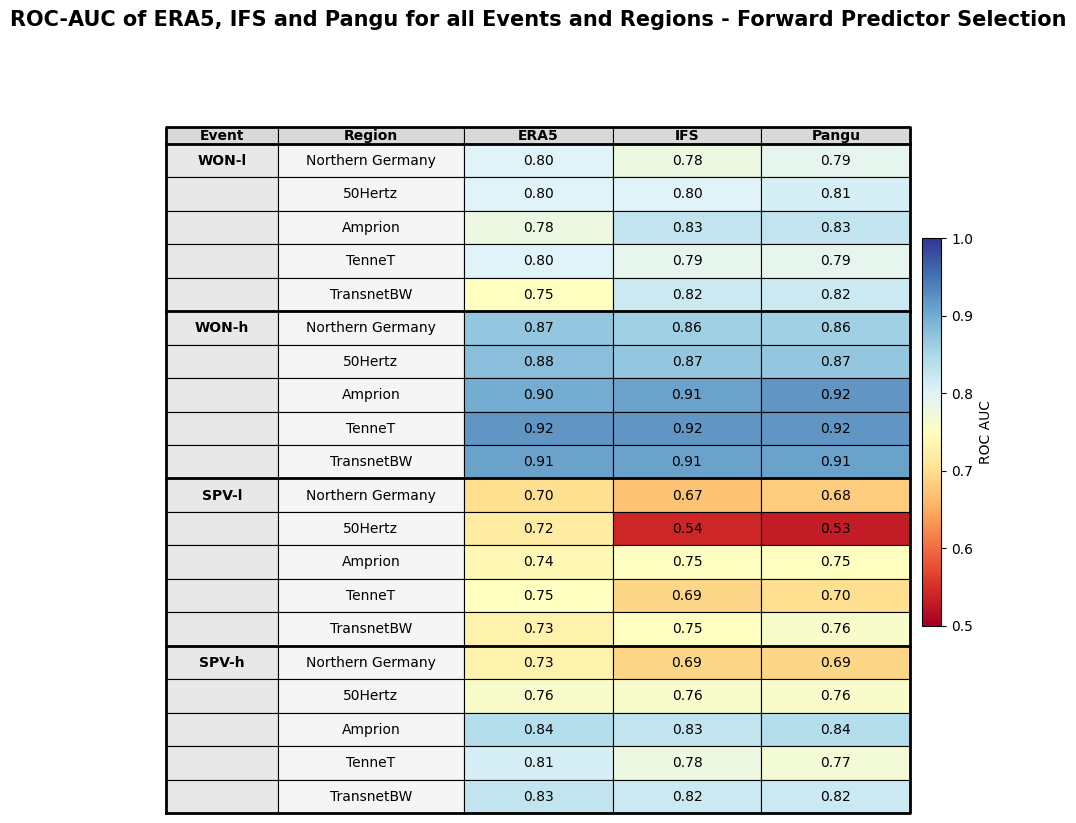

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import colormaps

# ============================================================
# 1. Alle vier Datensätze
# ============================================================

alle_daten = {
    "WON-l": data_wonl,
    "WON-h": data_wonh,
    "SPV-l": data_spvl,
    "SPV-h": data_spvh
}

# ============================================================
# 2. Daten zu einem gemeinsamen DataFrame zusammenführen
# ============================================================

tabellen = []

for event, regionen in alle_daten.items():

    for region, df in regionen.items():

        # ROC-AUC-Werte der drei Modelle extrahieren
        df_region = df.loc["ROC AUC"]

        # In DataFrame umwandeln
        df_region = df_region.to_frame().T

        # Event und Region ergänzen
        df_region.insert(0, "Region", region)
        df_region.insert(0, "Event", event)

        tabellen.append(df_region)

df_gesamt = pd.concat(tabellen, ignore_index=True)

# Modellspalten festlegen
modell_spalten = ["ERA5", "IFS", "Pangu"]

# Reihenfolge der Spalten
spalten = ["Event", "Region"] + modell_spalten
daten = df_gesamt[spalten].copy()

# ============================================================
# 3. Tabelleninhalte und Farben vorbereiten
# ============================================================

cmap = colormaps["RdYlBu"]
norm = Normalize(vmin=0.5, vmax=1.0)

cell_text = []
cell_colors = []

for _, row in daten.iterrows():

    # Zelltexte
    zeile = [
        str(row["Event"]),
        str(row["Region"])
    ]

    for col in modell_spalten:
        wert = row[col]

        zeile.append(
            f"{wert:.2f}" if pd.notna(wert) else ""
        )

    cell_text.append(zeile)

    # Zellfarben
    farben = ["#E8E8E8", "#F5F5F5"]

    for col in modell_spalten:
        wert = row[col]

        if pd.notna(wert):
            farben.append(cmap(norm(wert)))
        else:
            farben.append("white")

    cell_colors.append(farben)

# ============================================================
# 4. Tabelle zeichnen
# ============================================================

anzahl_zeilen = len(daten)
anzahl_spalten = len(spalten)

fig, ax = plt.subplots(
    figsize=(10, max(5, anzahl_zeilen * 0.42 + 1.5))
)

ax.axis("off")

table = ax.table(
    cellText=cell_text,
    cellColours=cell_colors,
    colLabels=["Event", "Region"] + modell_spalten,
    cellLoc="center",
    colLoc="center",
    colWidths=[0.15, 0.25, 0.20, 0.20, 0.20],
    bbox=[0, 0, 1, 0.90]
)

table.auto_set_font_size(False)
table.set_fontsize(10)

# Einheitliche schwarze Tabellenlinien
for (r, c), cell in table.get_celld().items():

    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

    if r == 0:
        cell.set_facecolor("#D9D9D9")
        cell.set_text_props(weight="bold")
    else:
        cell.set_height(0.90 / (anzahl_zeilen + 1))

# ============================================================
# 5. Events gruppieren und visuell abgrenzen
# ============================================================

# Eventnamen in der ersten Spalte zusammenfassen
start = 0
grenzen_zeilen = []

for event, gruppe in daten.groupby("Event", sort=False):

    anzahl = len(gruppe)

    for i in range(anzahl):

        zelle = table[(start + i + 1, 0)]
        zelle.set_facecolor("#E8E8E8")

        if i == 0:
            zelle.get_text().set_text(event)
            zelle.set_text_props(weight="bold")
        else:
            zelle.get_text().set_text("")

    # Trennlinie zwischen den Events
    if start > 0:
        grenzen_zeilen.append(start + 1)

    start += anzahl

# Tabelle rendern
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()

# Trennlinien zwischen den Events
for zeile in grenzen_zeilen:

    zelle = table[(zeile, 0)]
    bbox = zelle.get_window_extent(renderer=renderer)
    y = inv.transform((bbox.x0, bbox.y1))[1]

    ax.plot(
        [0, 1], [y, y],
        color="black",
        linewidth=2.0,
        transform=ax.transAxes,
        clip_on=False,
        zorder=100
    )

# Tabelle vollständig rendern
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()

# Äußeren Tabellenrahmen bestimmen
bbox_links = table[(0, 0)].get_window_extent(renderer)
bbox_rechts = table[(0, anzahl_spalten - 1)].get_window_extent(renderer)
bbox_unten = table[(anzahl_zeilen, 0)].get_window_extent(renderer)

x_links = inv.transform((bbox_links.x0, bbox_links.y0))[0]
x_rechts = inv.transform((bbox_rechts.x1, bbox_rechts.y0))[0]
y_oben = inv.transform((bbox_links.x0, bbox_links.y1))[1]
y_unten = inv.transform((bbox_unten.x0, bbox_unten.y0))[1]

# Äußerer Rahmen
ax.plot(
    [x_links, x_rechts, x_rechts, x_links, x_links],
    [y_unten, y_unten, y_oben, y_oben, y_unten],
    color="black",
    linewidth=2.0,
    transform=ax.transAxes,
    clip_on=False,
    zorder=101
)

# Dicke Trennlinie unter dem Header
header_bbox = table[(0, 0)].get_window_extent(renderer)
y_header = inv.transform((header_bbox.x0, header_bbox.y0))[1]

ax.plot(
    [x_links, x_rechts],
    [y_header, y_header],
    color="black",
    linewidth=2.0,
    transform=ax.transAxes,
    clip_on=False,
    zorder=102
)

# ============================================================
# 6. Titel und Farbskala
# ============================================================

ax.set_title(
    "ROC-AUC of ERA5, IFS and Pangu for all Events and Regions - Forward Predictor Selection",
    fontsize=15,
    fontweight="bold",
    pad=18
)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.025,
    pad=0.015
)

cbar.set_label("ROC AUC", fontsize=10)

# ============================================================
# 7. Als hochauflösendes PNG speichern
# ============================================================

plt.savefig(
    "Abbildungen_fertig/roc_auc_alleModelle_alleEvents_foreward_predictor_selection.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


**Tabelle Erstellen**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from matplotlib import colormaps

# ============================================================
# 1. Alle fünf Regionen
# ============================================================

alle_daten = {
    "WON-l": data_wonl,
    "WON-h": data_wonh,
    "SPV-l": data_spvl,
    "SPV-h": data_spvh#,
    # "TransnetBW": data_transnetBW
}

# ============================================================
# 2. Daten zu einem gemeinsamen DataFrame zusammenführen
# ============================================================

tabellen = []

for region, modelle in alle_daten.items():

    # ROC-AUC-Werte der Modelle extrahieren
    df_region = pd.concat(
        {
            modell: daten.loc["ROC AUC"]
            for modell, daten in modelle.items()
        },
        axis=1
    ).T

    df_region.index.name = "Forward predictor selection"
    df_region = df_region.reset_index()

    # Region ergänzen
    df_region.insert(0, "Region", region)

    tabellen.append(df_region)

df_gesamt = pd.concat(tabellen, ignore_index=True)

# Lag-Spalten automatisch erkennen
lag_spalten = [
    col for col in df_gesamt.columns
    if col.startswith("FPS")
]

# Lags in der richtigen Reihenfolge sortieren
lag_spalten = sorted(
    lag_spalten,
    key=lambda x: int(x.replace("FPS ", ""))
)

# ============================================================
# 3. Tabelleninhalte und Farben vorbereiten
# ============================================================

spalten = ["Region", "Forward predictor selection"] + lag_spalten
daten = df_gesamt[spalten].copy()

cmap = colormaps["RdYlBu"]
norm = Normalize(vmin=0.5, vmax=1.0)

cell_text = []
cell_colors = []

for _, row in daten.iterrows():

    # Zelltexte
    zeile = [
        str(row["Region"]),
        str(row["Forward predictor selection"])
    ]

    for col in lag_spalten:
        wert = row[col]
        zeile.append(
            f"{wert:.2f}" if pd.notna(wert) else ""
        )

    cell_text.append(zeile)

    # Zellfarben
    farben = ["#E8E8E8", "#F5F5F5"]

    for col in lag_spalten:
        wert = row[col]

        if pd.notna(wert):
            farben.append(cmap(norm(wert)))
        else:
            farben.append("white")

    cell_colors.append(farben)

# ============================================================
# 4. Tabelle zeichnen
# ============================================================

anzahl_zeilen = len(daten)
anzahl_spalten = len(spalten)

fig, ax = plt.subplots(
    figsize=(12, max(5, anzahl_zeilen * 0.42 + 1.5))
)

ax.axis("off")

table = ax.table(
    cellText=cell_text,
    cellColours=cell_colors,
    colLabels=["Event", "Region"] + lag_spalten,
    cellLoc="center",
    colLoc="center",
    colWidths=[0.1, 0.1425] + [0.1425] * len(lag_spalten),
    bbox=[0, 0, 1, 0.90]
)

table.auto_set_font_size(False)
table.set_fontsize(10)

# Einheitliche Zellrahmen und Zeilenhöhen
# Einheitliche schwarze Tabellenlinien
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

    if r == 0:
        cell.set_facecolor("#D9D9D9")
        cell.set_text_props(weight="bold")
    else:
        cell.set_height(0.90 / (anzahl_zeilen + 1))

# ============================================================
# 5. Regionen gruppieren und visuell abgrenzen
# ============================================================
# Regionsnamen in der ersten Spalte zusammenfassen
start = 0
grenzen_zeilen = []

for region, gruppe in daten.groupby("Region", sort=False):
    anzahl = len(gruppe)

    for i in range(anzahl):
        zelle = table[(start + i + 1, 0)]
        zelle.set_facecolor("#E8E8E8")

        if i == 0:
            zelle.get_text().set_text(region)
            zelle.set_text_props(weight="bold")
        else:
            zelle.get_text().set_text("")

    # Erste Datenzeile jeder Region merken, außer der ersten Region
    if start > 0:
        grenzen_zeilen.append(start + 1)

    start += anzahl

# Tabelle fertig layouten
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()

# Trennlinien exakt an den Zellgrenzen zeichnen
for zeile in grenzen_zeilen:
    zelle = table[(zeile, 0)]
    bbox = zelle.get_window_extent(renderer=renderer)
    y = inv.transform((bbox.x0, bbox.y1))[1]

    ax.plot(
        [0, 1], [y, y],
        color="black",
        linewidth=2.0,
        transform=ax.transAxes,
        clip_on=False,
        zorder=100
    )

# Tabelle vollständig rendern, damit die Zellpositionen feststehen
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()

# Äußeren Tabellenrahmen anhand der tatsächlichen Zellgrenzen bestimmen
bbox_links = table[(0, 0)].get_window_extent(renderer)
bbox_rechts = table[(0, anzahl_spalten - 1)].get_window_extent(renderer)
bbox_unten = table[(anzahl_zeilen, 0)].get_window_extent(renderer)

x_links = inv.transform((bbox_links.x0, bbox_links.y0))[0]
x_rechts = inv.transform((bbox_rechts.x1, bbox_rechts.y0))[0]
y_oben = inv.transform((bbox_links.x0, bbox_links.y1))[1]
y_unten = inv.transform((bbox_unten.x0, bbox_unten.y0))[1]

# Äußerer Rahmen: dicker als die normalen Zelllinien
ax.plot(
    [x_links, x_rechts, x_rechts, x_links, x_links],
    [y_unten, y_unten, y_oben, y_oben, y_unten],
    color="black",
    linewidth=2.0,
    transform=ax.transAxes,
    clip_on=False,
    zorder=101
)

# Dicke Trennlinie direkt unter dem Header
header_bbox = table[(0, 0)].get_window_extent(renderer)
y_header = inv.transform((header_bbox.x0, header_bbox.y0))[1]

ax.plot(
    [x_links, x_rechts],
    [y_header, y_header],
    color="black",
    linewidth=2.0,
    transform=ax.transAxes,
    clip_on=False,
    zorder=102
)
# ============================================================
# 6. Titel und Farbskala
# ============================================================

ax.set_title(
    "ROC-AUC of Index for all Regions forward predictor selection",
    fontsize=15,
    fontweight="bold",
    pad=18
)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.025,
    pad=0.015
)

cbar.set_label("ROC AUC", fontsize=10)

# ============================================================
# 7. Als hochauflösendes PNG speichern
# ============================================================

plt.savefig(
    "Abbildungen_fertig/roc_auc_alleModelle_forwardpredictorselection.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

TypeError: unsupported format string passed to Series.__format__

**Plotten**

In [79]:
extreme_event_type = 'SPV-h'

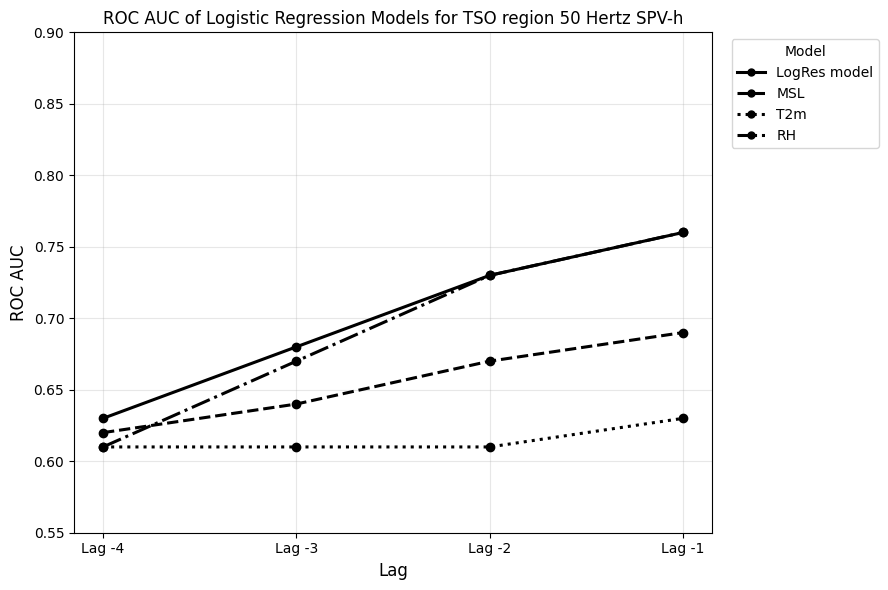

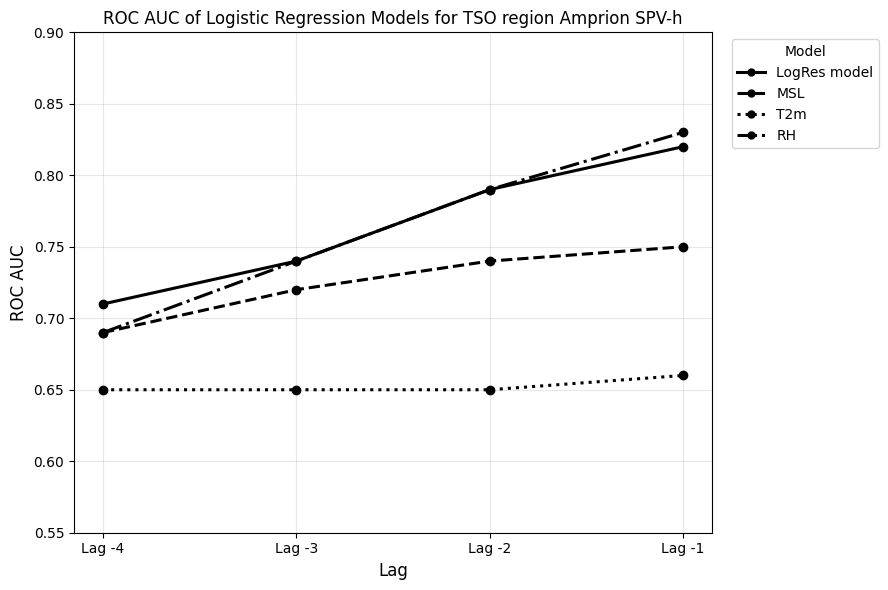

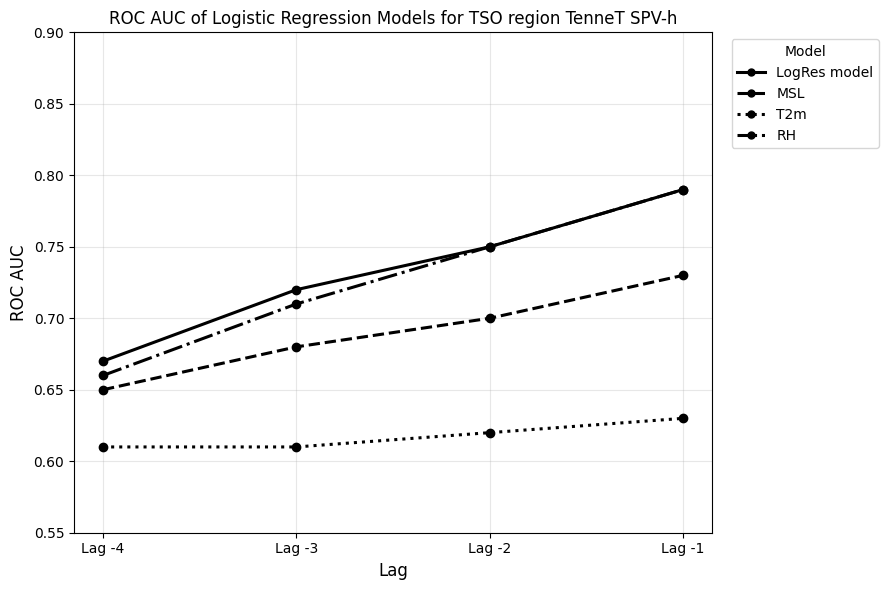

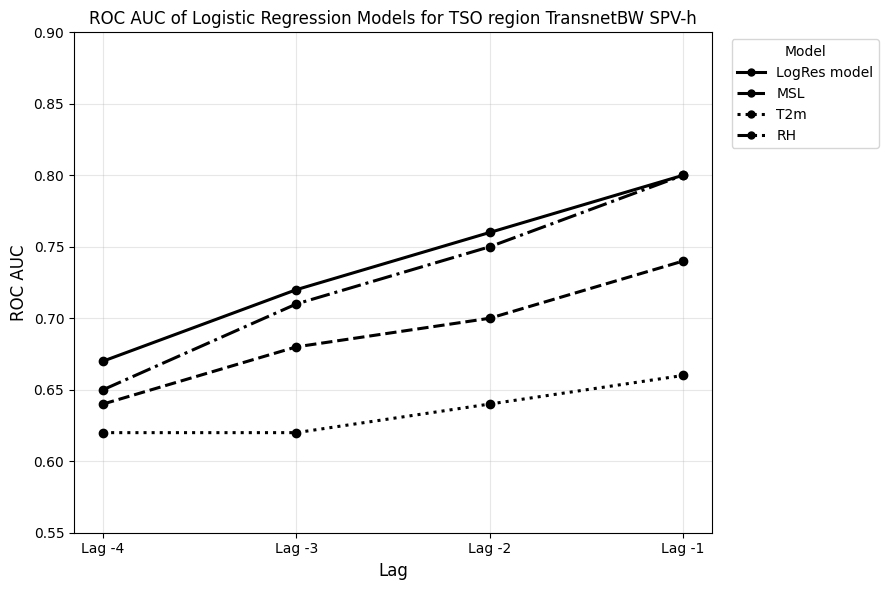

In [80]:
datasets = {
    "50 Hertz": data_50hertz,
    "Amprion": data_amprion,
    "TenneT": data_tennet,
    "TransnetBW": data_transnetBW
}
for region_name, data in datasets.items():
    region = region_name
    # Reihenfolge der Lags: -4 bis -1
    lags = ["Lag -4", "Lag -3", "Lag -2", "Lag -1"]

    # Einheitliche Farbe für alle Modelle
    line_color = "black"

    # Linienstile = Modelle
    linestyles = {
        "LogRes model": "-",
        "MSL": "--",
        "T2m": ":",
        "RH": "-."
    }

    fig, ax = plt.subplots(figsize=(9, 6))

    # Modelle plotten
    for model, df in data.items():

        values = [
            df.loc["ROC AUC", lag]
            for lag in lags
        ]

        ax.plot(
            lags,
            values,
            color=line_color,
            linestyle=linestyles[model],
            linewidth=2.2,
            marker="o",
            markersize=6
        )

    # Achsen
    ax.set_xlabel("Lag", fontsize=12)
    ax.set_ylabel("ROC AUC", fontsize=12)

    ax.set_ylim(0.55, 0.90)

    ax.grid(True, alpha=0.3)

    # Legende nur für Modelle
    model_handles = [
        Line2D(
            [0], [0],
            color=line_color,
            linestyle=linestyles[model],
            linewidth=2.2,
            marker="o",
            markersize=5,
            label=model
        )
        for model in data
    ]

    ax.legend(
        handles=model_handles,
        title="Model",
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00)
    )
    plt.title(f"ROC AUC of Logistic Regression Models for TSO region {region} {extreme_event_type}")
    plt.tight_layout()
    savepath = f"fig/LogRes_new/prepPangu/TSO_roc_auc_logres_{region}_{extreme_event_type}.png"
    os.makedirs(os.path.dirname(savepath), exist_ok=True)
    plt.savefig(savepath, dpi=300)
    plt.show()
    plt.close()

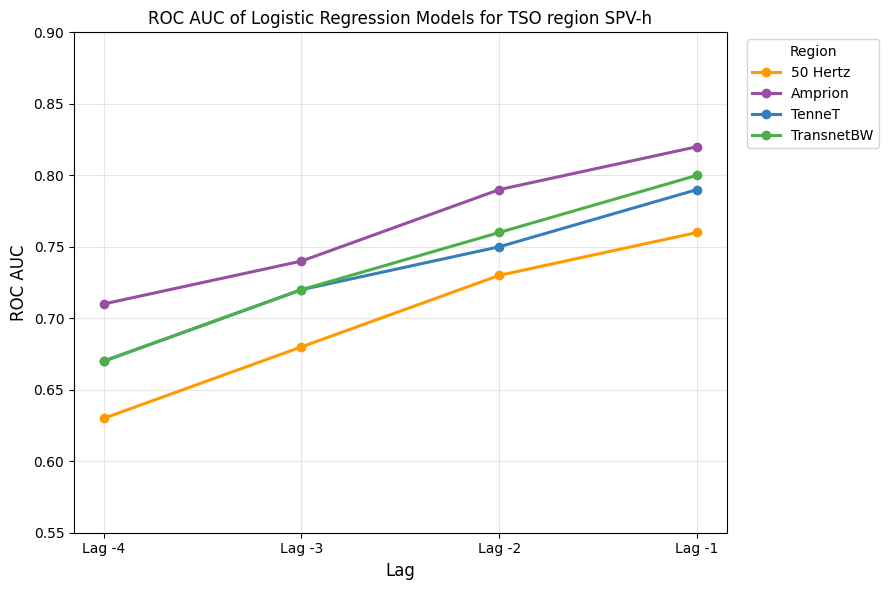

: 

In [ ]:
datasets = {
    "50 Hertz": data_50hertz,
    "Amprion": data_amprion,
    "TenneT": data_tennet,
    "TransnetBW": data_transnetBW
}

# Jetzt von Lag -4 nach Lag -1
lags = ["Lag -4", "Lag -3", "Lag -2", "Lag -1"]

colors = {
    "TransnetBW": "#4DAF4A",
    "TenneT": "#377EB8",
    "50 Hertz": "#FF9A01",
    "Amprion": "#984EA3",
}

fig, ax = plt.subplots(figsize=(9, 6))

for region, data in datasets.items():

    # Nur LogRes model
    df = data["LogRes model"]

    values = [
        df.loc["ROC AUC", lag]
        for lag in lags
    ]

    ax.plot(
        lags,
        values,
        color=colors[region],
        linestyle="-",
        linewidth=2.2,
        marker="o",
        markersize=6,
        label=region
    )

ax.set_xlabel("Lag", fontsize=12)
ax.set_ylabel("ROC AUC", fontsize=12)

# Feste y-Achse
ax.set_ylim(0.55, 0.9)

ax.grid(True, alpha=0.3)

# Legende außerhalb
ax.legend(
    title="Region",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.00)
)
plt.title(f"ROC AUC of Logistic Regression Models for TSO region {extreme_event_type}")
plt.tight_layout()
savepath = f"fig/LogRes_new/prepPangu/TSO_roc_auc_logres_{extreme_event_type}.png"
os.makedirs(os.path.dirname(savepath), exist_ok=True)
plt.savefig(savepath, dpi=300)
plt.show()

In [2]:
df = xr.open_dataset("data/ifs_hres/v_component_of_wind/ifs_hres_v_component_of_wind_2019-2020_DJF.nc")

In [3]:
df

<xarray.Dataset> Size: 2GB
Dimensions:               (time: 180, prediction_timedelta: 16, latitude: 289,
                           longitude: 561)
Coordinates:
  * time                  (time) datetime64[ns] 1kB 2019-12-01 ... 2020-02-28...
  * prediction_timedelta  (prediction_timedelta) int64 128B 6 12 18 ... 84 90 96
  * latitude              (latitude) float32 1kB 12.0 12.25 12.5 ... 83.75 84.0
  * longitude             (longitude) float32 2kB -90.0 -89.75 ... 49.75 50.0
    level                 int32 4B ...
Data variables:
    v_component_of_wind   (time, prediction_timedelta, latitude, longitude) float32 2GB ...

## WON/ SPV Vertielung mean über NUTS Zonen plotten

In [61]:
df_event = pd.read_csv('data/prepared/WON_daily_subcountry_prepared.csv')

In [23]:
nuts = gpd.read_file('data/NUTS_RG_20M_2024_3035.shp')

In [24]:
# Deutsche NUTS-2-Regionen auswählen
nuts_de = nuts[
    (nuts["CNTR_CODE"] == "DE") &
    (nuts["LEVL_CODE"] == 2)
].copy()

df_de = df_event[df_event["NUTS_ID"].str.startswith("DE")].copy()

# 2. Mittleren WON-Wert je NUTS-Zone berechnen
mean_won = (
    df_de.groupby("NUTS_ID", as_index=False)["WON"]
    .mean()
)

# Mittelwerte verknüpfen
nuts_de = nuts_de.merge(
    mean_won,
    on="NUTS_ID",
    how="left"
)

# Karte plotten
fig, ax = plt.subplots(figsize=(9, 11))
nuts_de_plot = nuts_de.to_crs(epsg=4326)

nuts_de_plot.plot(
    column="WON",
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.6,
    legend=True,
    legend_kwds={"label": "Mean WON", "shrink": 0.7},
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "No data"
    },
    ax=ax
)

ax.set_title("Mean WON CF 1979–2025 JJA in Germany")

# Koordinatenachsen
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Achsenbeschriftungen formatieren
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f°"))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f°"))


ax.set_axis_on()
plt.tight_layout()
plt.show()

NameError: name 'df_event' is not defined

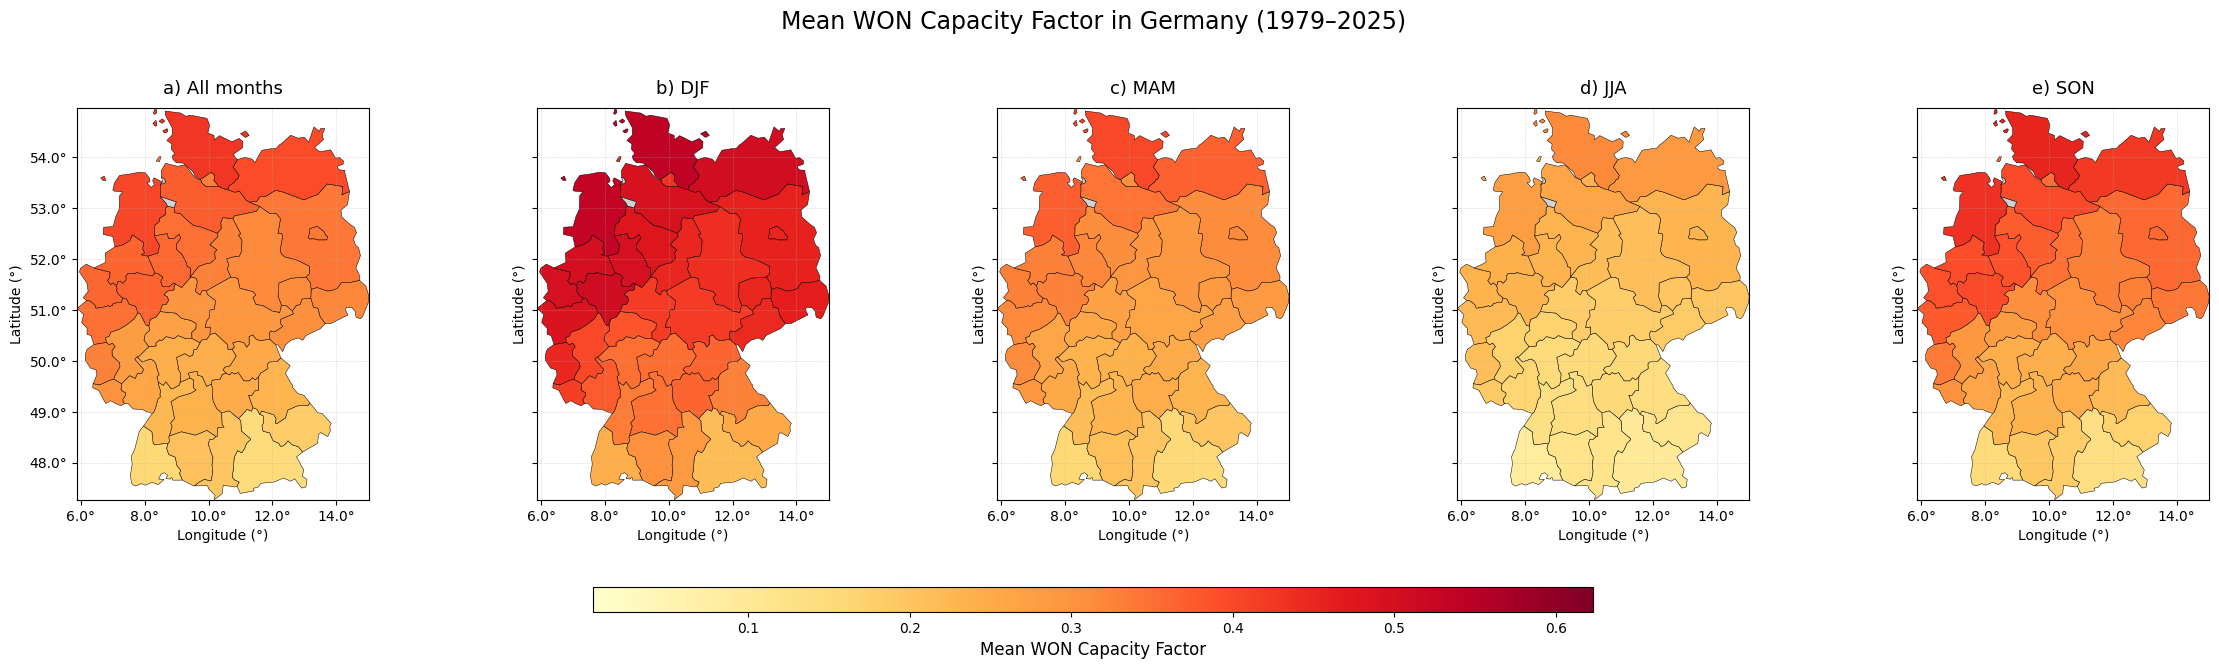

In [62]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# --------------------------------------------------
# 1. Daten vorbereiten
# --------------------------------------------------

df_plot = df_event.copy()
df_plot["Date"] = pd.to_datetime(df_plot["Date"])
df_plot["month"] = df_plot["Date"].dt.month

# Deutsche NUTS-2-Regionen
nuts_de = nuts[
    (nuts["CNTR_CODE"] == "DE") &
    (nuts["LEVL_CODE"] == 2)
].copy()

# In geografische Koordinaten transformieren
nuts_de = nuts_de.to_crs(epsg=4326)

# --------------------------------------------------
# 2. Monate und Jahreszeiten definieren
# --------------------------------------------------

periods = {
    "All months": list(range(1, 13)),
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11]
}

# Mittlere SPV-Werte für jede Periode berechnen
mean_data = {}

for period, months in periods.items():

    df_period = df_plot[df_plot["month"].isin(months)]

    mean_data[period] = (
        df_period.groupby("NUTS_ID")["WON"]
        .mean()
        .rename("WON")
    )

# --------------------------------------------------
# 3. Gemeinsame Farbskala bestimmen
# --------------------------------------------------

all_values = pd.concat(mean_data.values()).dropna()

vmin = all_values.min()
vmax = all_values.max()

cmap = "YlOrRd"
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

# Einheitliche Kartenausschnitte
xmin, ymin, xmax, ymax = nuts_de.total_bounds

# --------------------------------------------------
# 4. Fünf Karten nebeneinander plotten
# --------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=5,
    figsize=(25, 7),
    sharex=True,
    sharey=True
)

labels = ["a)", "b)", "c)", "d)", "e)"]

for ax, (period, values), label in zip(
    axes, mean_data.items(), labels
):

    # Mittelwerte mit Geometrien verbinden
    map_data = nuts_de.merge(
        values.reset_index(),
        on="NUTS_ID",
        how="left"
    )

    map_data.plot(
        column="WON",
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.35,
        missing_kwds={
            "color": "lightgrey",
            "edgecolor": "black"
        },
        ax=ax
    )

    # Einheitlicher Kartenausschnitt
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # Subplotüberschrift mit Nummerierung
    ax.set_title(
        f"{label} {period}",
        fontsize=13,
        pad=10
    )

    # Koordinatenachsen
    ax.set_xlabel("Longitude (°)", fontsize=10)
    ax.set_ylabel("Latitude (°)", fontsize=10)

    ax.xaxis.set_major_formatter(
        mticker.FormatStrFormatter("%.1f°")
    )
    ax.yaxis.set_major_formatter(
        mticker.FormatStrFormatter("%.1f°")
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.4,
        alpha=0.5
    )

    ax.set_axis_on()

# Gemeinsame Überschrift
fig.suptitle(
    "Mean WON Capacity Factor in Germany (1979–2025)",
    fontsize=17,
    y=0.98
)

# Platz für die Colorbar unterhalb der Karten reservieren
fig.subplots_adjust(
    left=0.06,
    right=0.98,
    top=0.84,
    bottom=0.28,
    wspace=0.001
)

# Gemeinsame Colorbar weiter nach unten setzen
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar_ax = fig.add_axes([0.30, 0.12, 0.40, 0.035])
cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Mean WON Capacity Factor", fontsize=12)

plt.show()

## Case Study ERA5 und CF Plots 

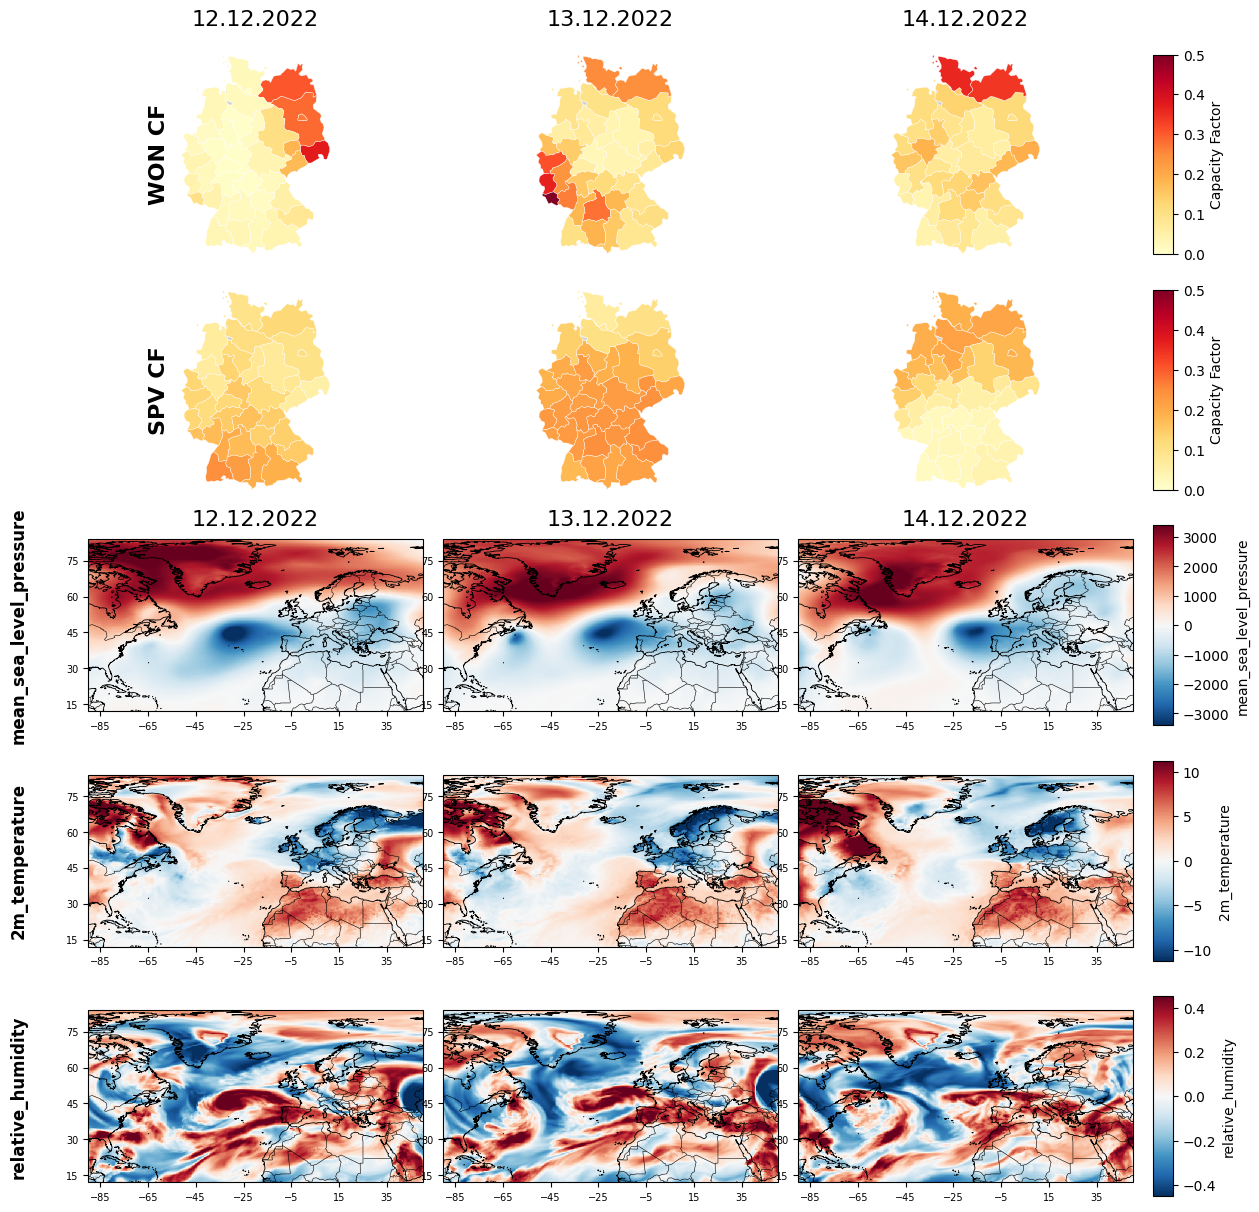

In [28]:
# Zeitraum
start_date = "2022-12-12"
end_date   = "2022-12-14"

# ERA5 Variablen
era5_variables = [
    "mean_sea_level_pressure",
    # "geopotential",
    # "v_component_of_wind",
    "2m_temperature",
    "relative_humidity"
]

# ERA5 Einstellungen
era5_base = r"data/ERA5/prepared/DJF_anom"

# CSV-Dateien
spv_file = r"data/prepared/SPV_daily_subcountry_prepared_DJF.csv"
won_file = r"data/prepared/WON_daily_subcountry_prepared_DJF.csv"

# Darstellung der ERA5-Variablen
era5_cmaps = {
    var: "RdBu_r" for var in era5_variables
}

# Gemeinsamer geografischer Ausschnitt ERA5
extent = [-90, 50, 12, 84]


# ==================================================
# 2. DATEN LADEN
# ==================================================

spv = pd.read_csv(spv_file, parse_dates=["Date"])
won = pd.read_csv(won_file, parse_dates=["Date"])

# Nur ausgewählten Zeitraum behalten
spv = spv[
    spv["Date"].isin(pd.date_range(start_date, end_date, freq="D"))
]

won = won[
    won["Date"].isin(pd.date_range(start_date, end_date, freq="D"))
]

# NUTS-Geometrien: nuts_de muss bereits geladen sein


# ==================================================
# 3. ERA5 DATEN LADEN
# ==================================================

# Dateien nach Variable und Jahr laden
era5_cache = {}

for var in era5_variables:

    for year in pd.date_range(start_date, end_date, freq="D").year.unique():

        path = os.path.join(
            era5_base,
            var,
            f"{var}_{year}_DJF_anom.nc"
        )

        if not os.path.exists(path):
            raise FileNotFoundError(path)

        ds = xr.open_dataset(path)

        # Variablennamen automatisch erkennen
        if var in ds.data_vars:
            da = ds[var]
        elif len(ds.data_vars) == 1:
            da = ds[list(ds.data_vars)[0]]
        else:
            raise ValueError(
                f"Variable {var} nicht eindeutig in {path}"
            )

        # Koordinaten erkennen
        lat_name = next(
            x for x in ["latitude", "lat"]
            if x in da.coords
        )

        lon_name = next(
            x for x in ["longitude", "lon"]
            if x in da.coords
        )

        era5_cache[(var, year)] = (
            da,
            lat_name,
            lon_name
        )


# Tageswerte extrahieren
era5_data = {}

for var in era5_variables:

    for date in pd.date_range(start_date, end_date, freq="D"):

        da, lat_name, lon_name = era5_cache[
            (var, date.year)
        ]

        day = np.datetime64(date.date())

        # Tageswert auswählen
        day_data = da.sel(
            time=day,
            method="nearest",
            tolerance=pd.Timedelta("12h")
        )

        # Auf 2D reduzieren, falls weitere Dimensionen
        # wie level vorhanden sind
        day_data = day_data.squeeze(drop=True)

        if day_data.ndim != 2:
            raise ValueError(
                f"{var}: Erwartet wird ein 2D-Feld, "
                f"erhalten: {day_data.dims}"
            )

        era5_data[(var, date)] = day_data


# ==================================================
# 4. GEMEINSAME FARB-SKALEN BERECHNEN
# ==================================================

# WON und SPV: gemeinsamer Wertebereich 0-1
cf_norm = mcolors.Normalize(
    vmin=0,
    vmax=0.5
)

# ERA5: symmetrische Farbskala je Variable
era5_norms = {}

for var in era5_variables:

    all_values = np.concatenate([
        era5_data[(var, date)].values.flatten()
        for date in pd.date_range(start_date, end_date, freq="D")
    ])

    all_values = all_values[np.isfinite(all_values)]

    vmax = np.nanpercentile(
        np.abs(all_values), 98
    )

    era5_norms[var] = mcolors.TwoSlopeNorm(
        vmin=-vmax,
        vcenter=0,
        vmax=vmax
    )


# ==================================================
# 5. FIGURE UND GRID ERSTELLEN
# ==================================================

n_rows = 8
n_cols = len(pd.date_range(start_date, end_date, freq="D"))

fig = plt.figure(
    figsize=(4 * n_cols + 2, 24)
)

gs = fig.add_gridspec(
    nrows=n_rows,
    ncols=n_cols + 1,
    width_ratios=[1] * n_cols + [0.06],
    hspace=0.18,
    wspace=0.08
)

# Zeilenbeschriftungen
row_names = [
    "WON CF",
    "SPV CF"
] + era5_variables


# ==================================================
# 6. WON UND SPV: DEUTSCHLANDKARTEN
# ==================================================

cf_datasets = [
    (won, "WON", "WON CF"),
    (spv, "SPV", "SPV CF")
]

for row, (df, variable, title) in enumerate(cf_datasets):

    for col, date in enumerate(pd.date_range(start_date, end_date, freq="D")):

        ax = fig.add_subplot(gs[row, col])

        # Tagesdaten auswählen
        daily = df[df["Date"] == date]

        # Mit NUTS-Geometrien verbinden
        geo = nuts_de.merge(
            daily[["NUTS_ID", variable]],
            on="NUTS_ID",
            how="left"
        )

        # Hintergrund für fehlende Werte
        geo[geo[variable].isna()].plot(
            ax=ax,
            color="lightgrey",
            edgecolor="white",
            linewidth=0.3
        )

        # Daten darstellen
        geo[geo[variable].notna()].plot(
            ax=ax,
            column=variable,
            cmap="YlOrRd",
            norm=cf_norm,
            edgecolor="white",
            linewidth=0.3
        )

        # Deutschlandausschnitt
        ax.set_xlim(
            nuts_de.total_bounds[0],
            nuts_de.total_bounds[2]
        )

        ax.set_ylim(
            nuts_de.total_bounds[1],
            nuts_de.total_bounds[3]
        )

        ax.set_aspect("equal")
        ax.set_axis_off()

        # Spaltenüberschriften
        if row == 0:
            ax.set_title(
                date.strftime("%d.%m.%Y"),
                fontsize=16,
                pad=10
            )

        # Zeilenbeschriftung
        if col == 0:
            ax.text(
                -0.08, 0.5,
                title,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=16,
                fontweight="bold"
            )

    # Gemeinsame Colorbar pro Zeile
    cax = fig.add_subplot(gs[row, -1])

    sm = ScalarMappable(
        norm=cf_norm,
        cmap="YlOrRd"
    )

    fig.colorbar(
        sm,
        cax=cax,
        label="Capacity Factor"
    )


# ==================================================
# 7. ERA5: EUROPA UND ATLANTIK
# ==================================================

for i, var in enumerate(era5_variables):

    row = i + 2

    for col, date in enumerate(pd.date_range(start_date, end_date, freq="D")):

        ax = fig.add_subplot(
            gs[row, col],
            projection=ccrs.PlateCarree()
        )

        da = era5_data[(var, date)]

        lat_name = era5_cache[
            (var, date.year)
        ][1]

        lon_name = era5_cache[
            (var, date.year)
        ][2]

        lon = da[lon_name].values
        lat = da[lat_name].values

        # ERA5-Daten darstellen
        mesh = ax.pcolormesh(
            lon,
            lat,
            da.values,
            cmap=era5_cmaps[var],
            norm=era5_norms[var],
            transform=ccrs.PlateCarree(),
            shading="auto"
        )

        # Geografischer Ausschnitt
        ax.set_extent(
            extent,
            crs=ccrs.PlateCarree()
        )

        # Kartenelemente
        ax.coastlines(
            resolution="50m",
            linewidth=0.6
        )

        ax.add_feature(
            cfeature.BORDERS,
            linewidth=0.4
        )

        ax.set_xticks(
            np.arange(-85, 51, 20), #-90, 50 #-45, 40, 
            crs=ccrs.PlateCarree()
        )

        ax.set_yticks(
            np.arange(15, 81, 15), #12, 84 #25, 75
            crs=ccrs.PlateCarree()
        )

        ax.tick_params(labelsize=7)

        # Spaltenüberschriften
        if row == 2:
            ax.set_title(
                date.strftime("%d.%m.%Y"),
                fontsize=16,
                pad=10
            )

        # Zeilenbeschriftung
        if col == 0:
            ax.text(
                -0.18, 0.5,
                var,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    # Gemeinsame Colorbar pro ERA5-Zeile
    cax = fig.add_subplot(gs[row, -1])

    sm = ScalarMappable(
        norm=era5_norms[var],
        cmap=era5_cmaps[var]
    )

    fig.colorbar(
        sm,
        cax=cax,
        label=var
    )


# ==================================================
# 8. FIGURE SPEICHERN
# ==================================================

# fig.suptitle(
#     "Daily WON, SPV and ERA5 anomalies",
#     fontsize=17,
#     fontweight="bold",
#     y=0.995
# )

plt.savefig(
    "fig/cas_study_daily_WON_SPV_ERA5_overview_SPV-l_zeitraumv2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

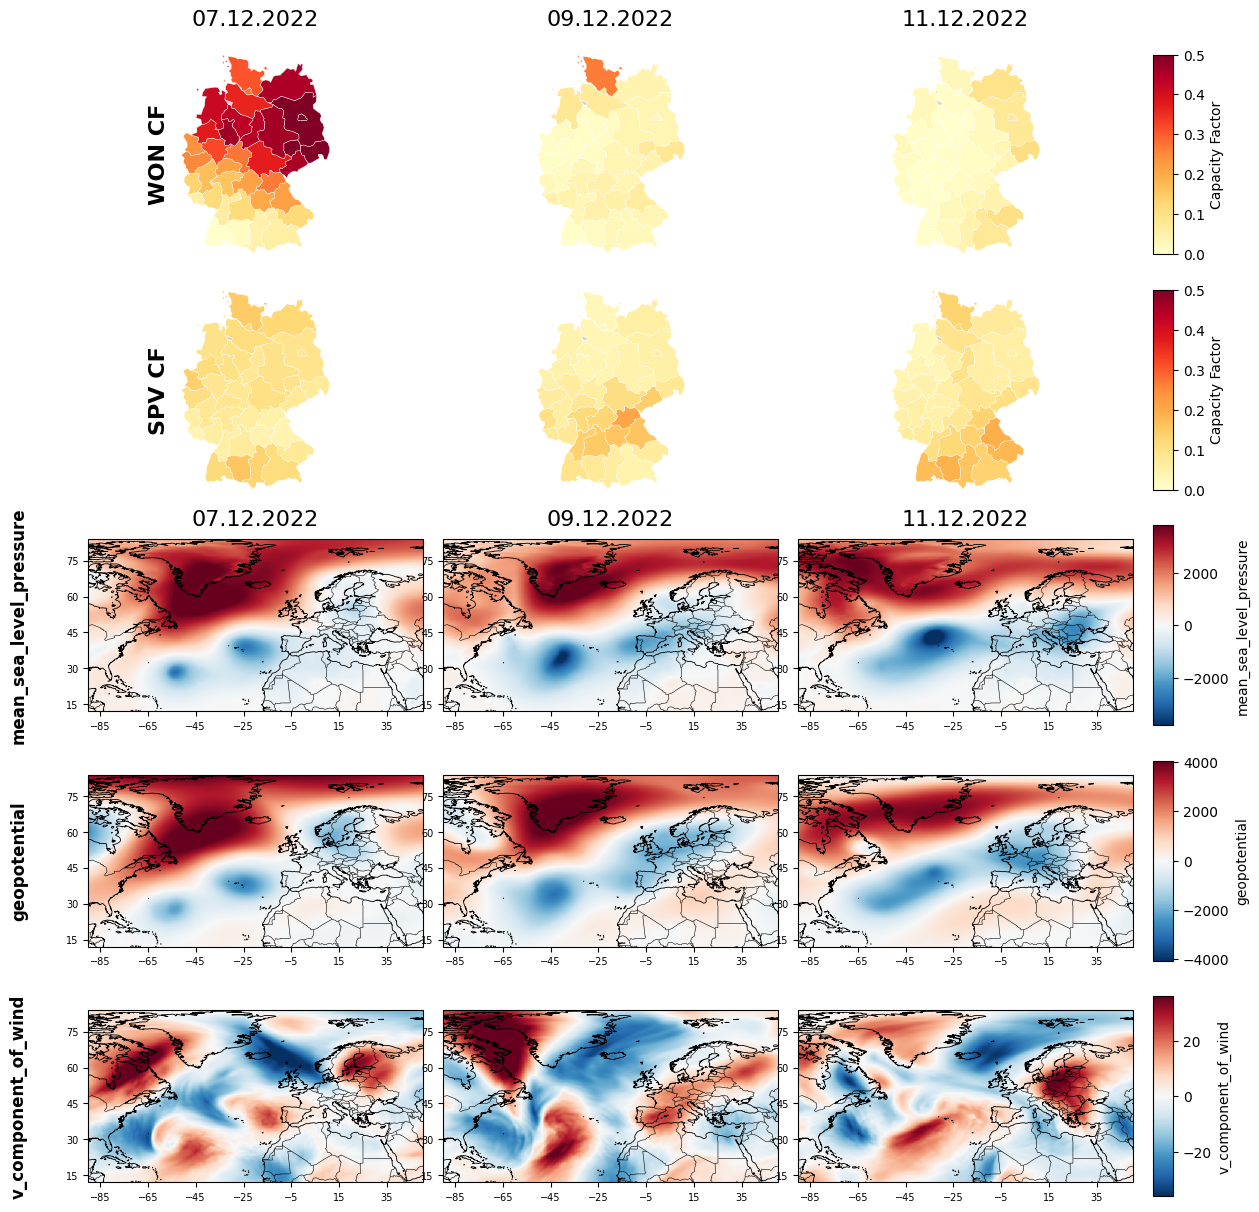

In [26]:
# Zeitraum
# Zeitraum
start_date = "2022-12-12"
end_date = "2022-12-14"

# Nur diese Tage plotten
plot_dates = pd.to_datetime([
    "2022-12-07",
    "2022-12-09",
    "2022-12-11",
    # "2022-12-10"
])

# ERA5 Variablen
era5_variables = [
    "mean_sea_level_pressure",
    "geopotential",
    "v_component_of_wind",
    # "2m_temperature",
    # "relative_humidity"
]

# ERA5 Einstellungen
era5_base = r"data/ERA5/prepared/DJF_anom"

# CSV-Dateien
spv_file = r"data/prepared/SPV_daily_subcountry_prepared_DJF.csv"
won_file = r"data/prepared/WON_daily_subcountry_prepared_DJF.csv"

# Darstellung der ERA5-Variablen
era5_cmaps = {
    var: "RdBu_r" for var in era5_variables
}

# Gemeinsamer geografischer Ausschnitt ERA5
extent = [-90, 50, 12, 84]


# ==================================================
# 2. DATEN LADEN
# ==================================================

spv = pd.read_csv(spv_file, parse_dates=["Date"])
won = pd.read_csv(won_file, parse_dates=["Date"])

# Nur ausgewählten Zeitraum behalten
spv = spv[spv["Date"].isin(plot_dates)]
won = won[won["Date"].isin(plot_dates)]

# NUTS-Geometrien: nuts_de muss bereits geladen sein


# ==================================================
# 3. ERA5 DATEN LADEN
# ==================================================

# Dateien nach Variable und Jahr laden
era5_cache = {}

for var in era5_variables:

    for year in pd.date_range(start_date, end_date, freq="D").year.unique():

        path = os.path.join(
            era5_base,
            var,
            f"{var}_{year}_DJF_anom.nc"
        )

        if not os.path.exists(path):
            raise FileNotFoundError(path)

        ds = xr.open_dataset(path)

        # Variablennamen automatisch erkennen
        if var in ds.data_vars:
            da = ds[var]
        elif len(ds.data_vars) == 1:
            da = ds[list(ds.data_vars)[0]]
        else:
            raise ValueError(
                f"Variable {var} nicht eindeutig in {path}"
            )

        # Koordinaten erkennen
        lat_name = next(
            x for x in ["latitude", "lat"]
            if x in da.coords
        )

        lon_name = next(
            x for x in ["longitude", "lon"]
            if x in da.coords
        )

        era5_cache[(var, year)] = (
            da,
            lat_name,
            lon_name
        )


# Tageswerte extrahieren
era5_data = {}

for var in era5_variables:

    for date in plot_dates:

        da, lat_name, lon_name = era5_cache[
            (var, date.year)
        ]

        day = np.datetime64(date.date())

        # Tageswert auswählen
        day_data = da.sel(
            time=day,
            method="nearest",
            tolerance=pd.Timedelta("12h")
        )

        # Auf 2D reduzieren, falls weitere Dimensionen
        # wie level vorhanden sind
        day_data = day_data.squeeze(drop=True)

        if day_data.ndim != 2:
            raise ValueError(
                f"{var}: Erwartet wird ein 2D-Feld, "
                f"erhalten: {day_data.dims}"
            )

        era5_data[(var, date)] = day_data


# ==================================================
# 4. GEMEINSAME FARB-SKALEN BERECHNEN
# ==================================================

# WON und SPV: gemeinsamer Wertebereich 0-1
cf_norm = mcolors.Normalize(
    vmin=0,
    vmax=0.5
)

# ERA5: symmetrische Farbskala je Variable
era5_norms = {}

for var in era5_variables:

    all_values = np.concatenate([
        era5_data[(var, date)].values.flatten()
        for date in plot_dates
    ])

    all_values = all_values[np.isfinite(all_values)]

    vmax = np.nanpercentile(
        np.abs(all_values), 98
    )

    era5_norms[var] = mcolors.TwoSlopeNorm(
        vmin=-vmax,
        vcenter=0,
        vmax=vmax
    )


# ==================================================
# 5. FIGURE UND GRID ERSTELLEN
# ==================================================

n_rows = 8
n_cols = len(plot_dates)

fig = plt.figure(
    figsize=(4 * n_cols + 2, 24)
)

gs = fig.add_gridspec(
    nrows=n_rows,
    ncols=n_cols + 1,
    width_ratios=[1] * n_cols + [0.06],
    hspace=0.18,
    wspace=0.08
)

# Zeilenbeschriftungen
row_names = [
    "WON CF",
    "SPV CF"
] + era5_variables


# ==================================================
# 6. WON UND SPV: DEUTSCHLANDKARTEN
# ==================================================

cf_datasets = [
    (won, "WON", "WON CF"),
    (spv, "SPV", "SPV CF")
]

for row, (df, variable, title) in enumerate(cf_datasets):

    for col, date in enumerate(plot_dates):

        ax = fig.add_subplot(gs[row, col])

        # Tagesdaten auswählen
        daily = df[df["Date"] == date]

        # Mit NUTS-Geometrien verbinden
        geo = nuts_de.merge(
            daily[["NUTS_ID", variable]],
            on="NUTS_ID",
            how="left"
        )

        # Hintergrund für fehlende Werte
        geo[geo[variable].isna()].plot(
            ax=ax,
            color="lightgrey",
            edgecolor="white",
            linewidth=0.3
        )

        # Daten darstellen
        geo[geo[variable].notna()].plot(
            ax=ax,
            column=variable,
            cmap="YlOrRd",
            norm=cf_norm,
            edgecolor="white",
            linewidth=0.3
        )

        # Deutschlandausschnitt
        ax.set_xlim(
            nuts_de.total_bounds[0],
            nuts_de.total_bounds[2]
        )

        ax.set_ylim(
            nuts_de.total_bounds[1],
            nuts_de.total_bounds[3]
        )

        ax.set_aspect("equal")
        ax.set_axis_off()

        # Spaltenüberschriften
        if row == 0:
            ax.set_title(
                date.strftime("%d.%m.%Y"),
                fontsize=16,
                pad=10
            )

        # Zeilenbeschriftung
        if col == 0:
            ax.text(
                -0.08, 0.5,
                title,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=16,
                fontweight="bold"
            )

    # Gemeinsame Colorbar pro Zeile
    cax = fig.add_subplot(gs[row, -1])

    sm = ScalarMappable(
        norm=cf_norm,
        cmap="YlOrRd"
    )

    fig.colorbar(
        sm,
        cax=cax,
        label="Capacity Factor"
    )


# ==================================================
# 7. ERA5: EUROPA UND ATLANTIK
# ==================================================

for i, var in enumerate(era5_variables):

    row = i + 2

    for col, date in enumerate(plot_dates):

        ax = fig.add_subplot(
            gs[row, col],
            projection=ccrs.PlateCarree()
        )

        da = era5_data[(var, date)]

        lat_name = era5_cache[
            (var, date.year)
        ][1]

        lon_name = era5_cache[
            (var, date.year)
        ][2]

        lon = da[lon_name].values
        lat = da[lat_name].values

        # ERA5-Daten darstellen
        mesh = ax.pcolormesh(
            lon,
            lat,
            da.values,
            cmap=era5_cmaps[var],
            norm=era5_norms[var],
            transform=ccrs.PlateCarree(),
            shading="auto"
        )

        # Geografischer Ausschnitt
        ax.set_extent(
            extent,
            crs=ccrs.PlateCarree()
        )

        # Kartenelemente
        ax.coastlines(
            resolution="50m",
            linewidth=0.6
        )

        ax.add_feature(
            cfeature.BORDERS,
            linewidth=0.4
        )

        ax.set_xticks(
            np.arange(-85, 51, 20), #-90, 50 #-45, 40, 
            crs=ccrs.PlateCarree()
        )

        ax.set_yticks(
            np.arange(15, 81, 15), #12, 84 #25, 75
            crs=ccrs.PlateCarree()
        )

        ax.tick_params(labelsize=7)

        # Spaltenüberschriften
        if row == 2:
            ax.set_title(
                date.strftime("%d.%m.%Y"),
                fontsize=16,
                pad=10
            )

        # Zeilenbeschriftung
        if col == 0:
            ax.text(
                -0.18, 0.5,
                var,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    # Gemeinsame Colorbar pro ERA5-Zeile
    cax = fig.add_subplot(gs[row, -1])

    sm = ScalarMappable(
        norm=era5_norms[var],
        cmap=era5_cmaps[var]
    )

    fig.colorbar(
        sm,
        cax=cax,
        label=var
    )


# ==================================================
# 8. FIGURE SPEICHERN
# ==================================================

# fig.suptitle(
#     "Daily WON, SPV and ERA5 anomalies",
#     fontsize=17,
#     fontweight="bold",
#     y=0.995
# )

plt.savefig(
    "fig/cas_study_daily_WON_SPV_ERA5_overview_WON-l_zeitraumv2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
from pathlib import Path
import re
import joblib
import pandas as pd

base_dir = Path(r"C:\Users\Luisa\Documents\GitHub\pw-work-new\fig\logRes_new\prepPangu")
model_paths = sorted(base_dir.rglob("*logistic_model_forward-predictor-selection*.pkl"))

feature_re = re.compile(r"^(?P<variable>.*?)_index_val1_lag(?P<lag>-?\d+)$")

rows = []

for model_path in model_paths:
    saved = joblib.load(model_path)
    features = [str(f) for f in saved.get("features", [])]

    # Erwartete Struktur: base_dir/REGION/SPV|WON/l|h/datei.pkl
    rel_parts = model_path.relative_to(base_dir).parts
    region = rel_parts[0] if len(rel_parts) >= 4 else ""
    energy_event = rel_parts[1] if len(rel_parts) >= 4 else ""
    extreme_event = rel_parts[2] if len(rel_parts) >= 4 else ""

    for feat in features:
        m = feature_re.match(feat)
        rows.append({
            "region": region,
            "energy_event": energy_event,   # SPV oder WON
            "extreme_event": extreme_event, # l oder h
            "model_file": model_path.name,
            "model_path": str(model_path),
            "feature_exact": feat,
            "variable": m.group("variable") if m else "",
            "lag": int(m.group("lag")) if m else ""
        })

df = pd.DataFrame(rows)

out_csv = base_dir / "forward_predictor_saved_features_with_region_event.csv"
df.to_csv(out_csv, index=False, encoding="utf-8-sig", sep=";", decimal=",")

print(f"CSV gespeichert unter: {out_csv}")

CSV gespeichert unter: C:\Users\Luisa\Documents\GitHub\pw-work-new\fig\logRes_new\prepPangu\forward_predictor_saved_features_with_region_event.csv


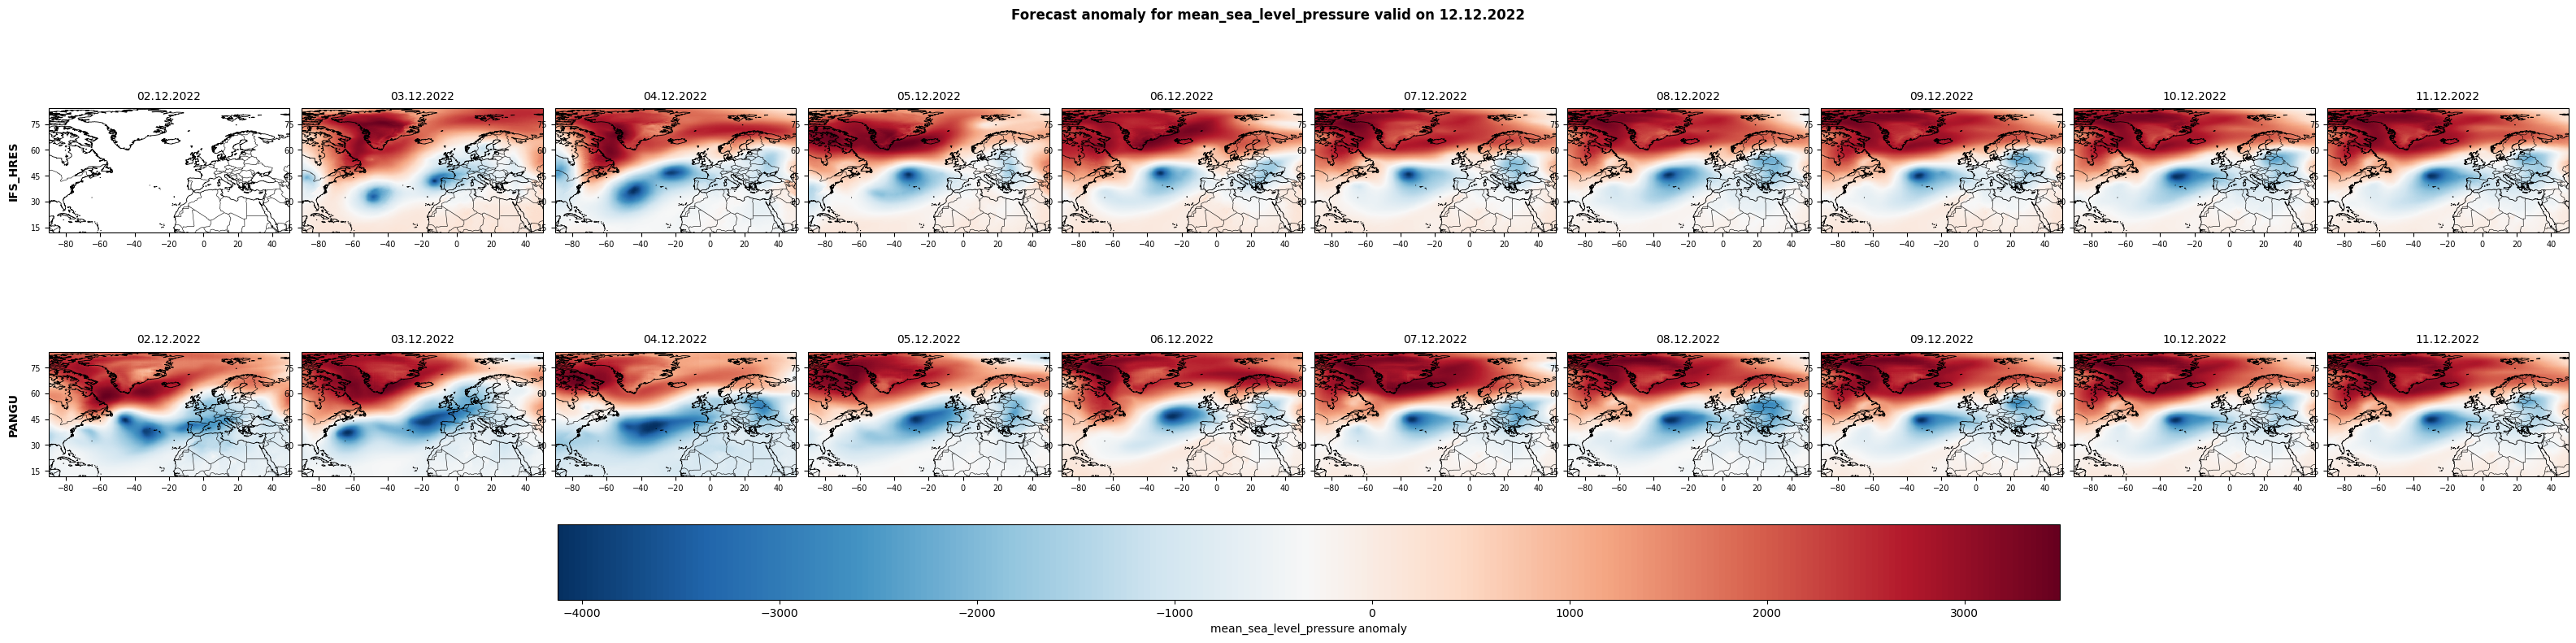

In [40]:
target_date = pd.Timestamp("2022-12-12")
target_var = "mean_sea_level_pressure"
lead_days = 10

init_dates = pd.date_range(
    target_date - pd.Timedelta(days=lead_days),
    target_date - pd.Timedelta(days=1),
    freq="D"
)

if "ds_pangu" not in globals():
    ds_pangu = xr.open_dataset(
        f"data/pangu/{target_var}/pangu_{target_var}_2022-2022_case_study.nc"
    )

if "ds_ifs" not in globals():
    ds_ifs = xr.open_dataset(
        f"data/ifs_hres/{target_var}/ifs_hres_{target_var}_2022-2022_case_study.nc"
    )

# Climatology for target day of year
clim = xr.open_dataset(f"data/climsmooth/clim_smooth_{target_var}.nc")
clim = clim.assign_coords(
    longitude=((clim.longitude + 180) % 360) - 180
).sortby("longitude")
clim = clim.sortby("latitude", ascending=False)
clim_target = clim.sel(dayofyear=target_date.dayofyear)
if target_var in clim.data_vars:
    clim_target = clim_target[target_var]
else:
    clim_target = clim_target

def prepare_model_data(ds, var_name, model_name):
    if isinstance(ds, xr.Dataset):
        if var_name in ds.data_vars:
            da = ds[var_name]
        else:
            da = ds
    else:
        da = ds

    if "longitude" in da.coords:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")
    if "latitude" in da.coords:
        da = da.sortby("latitude", ascending=False)

    if model_name == "pangu":
        if "level" in da.coords and var_name in {"geopotential", "v_component_of_wind", "relative_humidity"}:
            level_map = {"geopotential": 500, "v_component_of_wind": 300, "relative_humidity": 700}
            da = da.sel(level=level_map[var_name])
        return da

    if "level" in da.coords and var_name in {"geopotential", "v_component_of_wind", "relative_humidity"}:
        level_map = {"geopotential": 500, "v_component_of_wind": 300, "relative_humidity": 700}
        da = da.sel(level=level_map[var_name])

    return da

def daily_forecast_for_target(ds, init_time, target_day, var_name):
    da = prepare_model_data(ds, var_name, "pangu" if "pangu" in str(type(ds)).lower() else "ifs")
    if "prediction_timedelta" in da.coords:
        init_slice = da.sel(time=init_time, method="nearest")
        lead = init_slice.prediction_timedelta * np.timedelta64(1, "h")
        valid_time = init_slice.time + lead
        init_slice = init_slice.assign_coords(
            valid_time=("prediction_timedelta", valid_time.values)
        ).swap_dims({"prediction_timedelta": "valid_time"})
        daily = init_slice.sel(
            valid_time=slice(target_day, target_day + pd.Timedelta(days=1))
        ).mean(dim="valid_time")
    else:
        daily = da.sel(
            time=slice(target_day, target_day + pd.Timedelta(days=1))
        ).mean(dim="time")
    return daily

model_cfg = {
    "ifs_hres": ds_ifs,
    "pangu": ds_pangu
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=len(init_dates),
    figsize=(4 * len(init_dates), 8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    squeeze=False
)

for row, (model_name, ds_model) in enumerate(model_cfg.items()):
    for col, init_date in enumerate(init_dates):
        ax = axes[row, col]
        da = daily_forecast_for_target(ds_model, init_date, target_date, target_var)
        anom = da - clim_target

        if "longitude" in anom.coords and "latitude" in anom.coords:
            mesh = ax.pcolormesh(
                anom.longitude.values,
                anom.latitude.values,
                anom.values,
                cmap="RdBu_r",
                transform=ccrs.PlateCarree(),
                shading="auto"
            )
        else:
            mesh = ax.pcolormesh(
                anom.x.values,
                anom.y.values,
                anom.values,
                cmap="RdBu_r",
                transform=ccrs.PlateCarree(),
                shading="auto"
            )

        ax.set_extent([-90, 50, 12, 84], crs=ccrs.PlateCarree())
        ax.coastlines(resolution="50m", linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.4)
        ax.set_xticks(np.arange(-80, 51, 20), crs=ccrs.PlateCarree())
        ax.set_yticks(np.arange(15, 81, 15), crs=ccrs.PlateCarree())
        ax.tick_params(labelsize=7)

        if col == 0:
            ax.text(-0.12, 0.5, model_name.upper(), transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=10, fontweight="bold")
        ax.set_title(init_date.strftime("%d.%m.%Y"), fontsize=10, pad=8)

fig.suptitle(
    f"Forecast anomaly for {target_var} valid on {target_date:%d.%m.%Y}",
    fontsize=12,
    fontweight="bold",
    y=1.02
)

cbar = fig.colorbar(
    mesh,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    shrink=0.8,
    pad=0.2
)
cbar.set_label(f"{target_var} anomaly")

fig.subplots_adjust(
    bottom=0.3,
    top=1.0,
    wspace=0.05,
    hspace=0.15
)
plt.savefig(f"fig/case_study_forecast/forecast_anomaly_{target_var}_{target_date:%Y%m%d}.png", dpi=300)
plt.show()

Composite dimensions: ('latitude', 'longitude')
Composite shape: (289, 561)


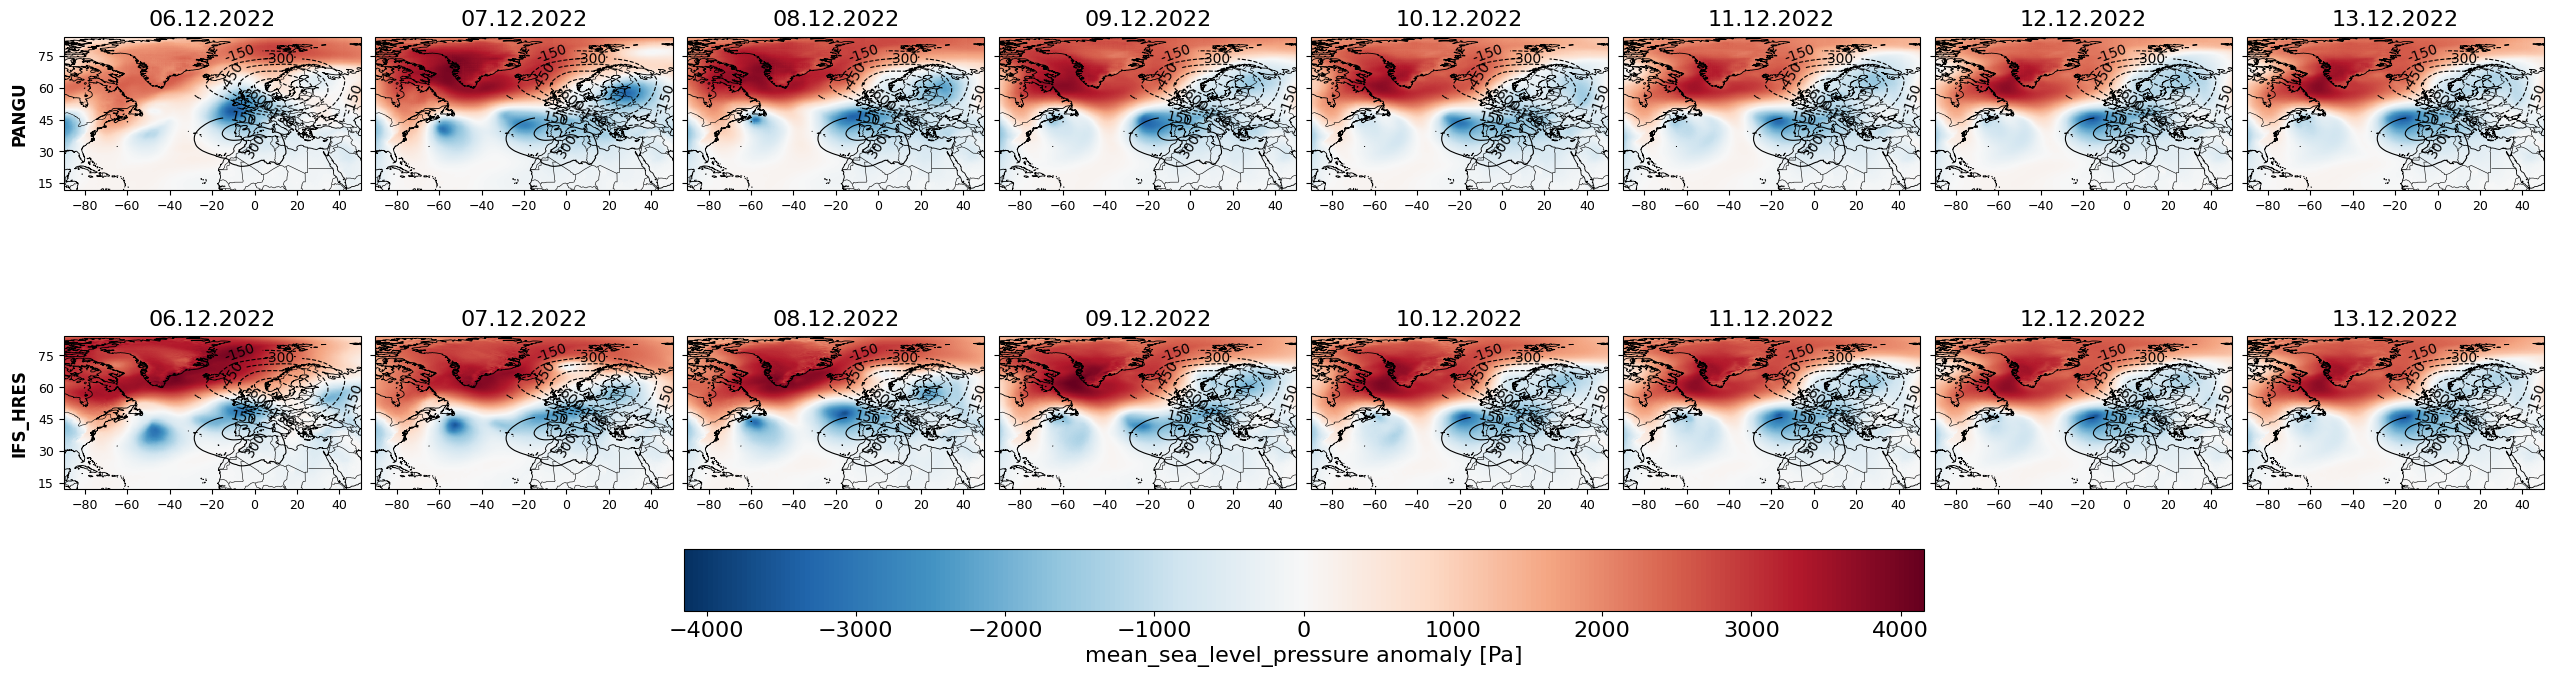

In [ ]:
target_date = pd.Timestamp("2022-12-11")
target_var = "mean_sea_level_pressure"
target_unit = "Pa"
region = "Norddeutschland"
energy_var = "WON"
extreme_event = "l"
lead_days = 8

init_dates = pd.date_range(
    target_date - pd.Timedelta(days=8),
    target_date - pd.Timedelta(days=1),
    freq="D"
)

ds_pangu = xr.open_dataset(
    f"data/pangu/{target_var}/pangu_{target_var}_2022-2022_case_study.nc"
)

ds_ifs = xr.open_dataset(
    f"data/ifs_hres/{target_var}/ifs_hres_{target_var}_2022-2022_case_study.nc"
)

# Climatology for target day of year
clim = xr.open_dataset(f"data/climsmooth/clim_smooth_{target_var}.nc")
clim = clim.assign_coords(
    longitude=((clim.longitude + 180) % 360) - 180
).sortby("longitude")
clim = clim.sortby("latitude", ascending=False)
clim_target = clim.sel(dayofyear=target_date.dayofyear)
if target_var in clim.data_vars:
    clim_target = clim_target[target_var]
else:
    clim_target = clim_target
# Load composite pattern
composite_path = (
    f"data/domino_output_coords_weatherbench/{energy_var}/100/"
    f"{energy_var}-{extreme_event}_{region}_{target_var}_EUROPE_1979_lags_-4_-3_-2_-1_0_bootstrap-composites_deseasonalized_DJF_anom.nc"
)

ds_composite = xr.open_dataset(composite_path)
composite = ds_composite.sel(index_val=1, lag=0)

# Select variable
if target_var in composite.data_vars:
    composite_anom = composite[target_var]
else:
    composite_anom = composite[list(composite.data_vars)[0]]

# Remove dimensions of size 1
composite_anom = composite_anom.squeeze(drop=True)

# Check remaining dimensions
print("Composite dimensions:", composite_anom.dims)
print("Composite shape:", composite_anom.shape)

# Standardize coordinates
if "longitude" in composite_anom.coords:
    composite_anom = composite_anom.assign_coords(
        longitude=((composite_anom.longitude + 180) % 360) - 180
    ).sortby("longitude")

if "latitude" in composite_anom.coords:
    composite_anom = composite_anom.sortby("latitude", ascending=False)
def prepare_model_data(ds, var_name, model_name):
    if isinstance(ds, xr.Dataset):
        if var_name in ds.data_vars:
            da = ds[var_name]
        else:
            da = ds
    else:
        da = ds

    if "longitude" in da.coords:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")
    if "latitude" in da.coords:
        da = da.sortby("latitude", ascending=False)

    if model_name == "pangu":
        if "level" in da.coords and var_name in {"geopotential", "v_component_of_wind", "relative_humidity"}:
            level_map = {"geopotential": 500, "v_component_of_wind": 300, "relative_humidity": 700}
            da = da.sel(level=level_map[var_name])
        return da

    if "level" in da.coords and var_name in {"geopotential", "v_component_of_wind", "relative_humidity"}:
        level_map = {"geopotential": 500, "v_component_of_wind": 300, "relative_humidity": 700}
        da = da.sel(level=level_map[var_name])

    return da

def daily_forecast_for_target(ds, init_time, target_day, var):
    # Forecast für den gewünschten Initialisierungszeitpunkt
    da = ds[var].sel(time=init_time)

    # Lead time von Stunden in timedelta64 umwandeln
    lead_time = pd.to_timedelta(
        da.prediction_timedelta.values, unit="h"
    )

    # Tatsächliche Gültigkeitszeiten berechnen
    valid_times = init_time + lead_time

    da = da.assign_coords(valid_time=("prediction_timedelta", valid_times))
    da = da.swap_dims({"prediction_timedelta": "valid_time"})

    # Erwartete Zeitpunkte: 00, 06, 12 und 18 UTC
    expected_times = pd.date_range(
        start=target_day,
        periods=4,
        freq="6h"
    )

    # Vorhersagen für den Zieltag auswählen
    daily_values = da.sel(valid_time=expected_times)

    # Prüfen, ob alle vier Zeitpunkte vorhanden sind
    if len(daily_values.valid_time) != 4:
        return None

    if not np.array_equal(
        daily_values.valid_time.values,
        expected_times.values
    ):
        return None

    # Tagesmittelwert berechnen
    return daily_values.mean(dim="valid_time")

model_cfg = {
    "pangu": ds_pangu,
    "ifs_hres": ds_ifs
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=len(init_dates),
    figsize=(4 * len(init_dates), 8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    squeeze=False
)
all_anomalies = []

for model_name, ds_model in model_cfg.items():
    for init_date in init_dates:

        da = daily_forecast_for_target(
            ds_model,
            init_date,
            target_date,
            target_var
        )

        if da is None:
            print(f"Skipping {model_name}, init: {init_date}")
            continue


        clim_interp = clim_target.interp(
            longitude=da.longitude,
            latitude=da.latitude
        )

        anom = da - clim_interp

        all_anomalies.append(anom.values.flatten())

vmax = np.nanmax(
    np.abs(np.concatenate(all_anomalies))
)
vmin = -vmax

for row, (model_name, ds_model) in enumerate(model_cfg.items()):
    for col, init_date in enumerate(init_dates):
        ax = axes[row, col]
        da = daily_forecast_for_target(ds_model, init_date, target_date, target_var)
        anom = da - clim_target

        if "longitude" in anom.coords and "latitude" in anom.coords:
            mesh = ax.pcolormesh(
                anom.longitude.values,
                anom.latitude.values,
                anom.values,
                cmap="RdBu_r",
                vmin=vmin,
                vmax=vmax,
                transform=ccrs.PlateCarree(),
                shading="auto"
            )
        else:
            mesh = ax.pcolormesh(
                anom.x.values,
                anom.y.values,
                anom.values,
                cmap="RdBu_r",
                vmin=vmin,
                vmax=vmax,
                transform=ccrs.PlateCarree(),
                shading="auto"
            )
        # Overlay composite anomaly as contour lines
        contour = ax.contour(
            composite_anom.longitude.values,
            composite_anom.latitude.values,
            composite_anom.values,
            levels=10,
            colors="black",
            linewidths=0.8,
            transform=ccrs.PlateCarree()
        )
        ax.clabel(
            contour,
            inline=True,
            fontsize=10,
            fmt="%.0f"
        )

        ax.set_extent([-90, 50, 12, 84], crs=ccrs.PlateCarree())
        ax.coastlines(resolution="50m", linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.4)
        ax.set_xticks(np.arange(-80, 51, 20), crs=ccrs.PlateCarree())
        ax.set_yticks(np.arange(15, 81, 15), crs=ccrs.PlateCarree())
        ax.tick_params(labelsize=9)

        if col == 0:
            ax.text(-0.12, 0.5, model_name.upper(), transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=12, fontweight="bold")
        ax.set_title(init_date.strftime("%d.%m.%Y"), fontsize=16, pad=8)
# Synchronize y-axis extent across all subplots
for ax in axes.ravel():
    ax.set_extent([-90, 50, 12, 84], crs=ccrs.PlateCarree())

# Show y-axis labels only on the first column
for row in range(2):
    for col in range(1, len(init_dates)):
        axes[row, col].tick_params(
            axis="y",
            labelleft=False
        )
# fig.suptitle(
#     f"Forecast anomaly for {target_var} valid on {target_date:%d.%m.%Y}",
#     fontsize=18,
#     fontweight="bold",
#     y=1.0
# )

cbar = fig.colorbar(
    mesh,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    shrink=0.5,
    pad=0.2
)
cbar.set_label(f"{target_var} anomaly [{target_unit}]", fontsize=16)
cbar.ax.tick_params(labelsize=16)

fig.subplots_adjust(
    bottom=0.3,
    top=1.0,
    wspace=0.05,
    hspace=0.15
)
plt.savefig(f"fig/case_study_forecast/forecast_anomaly_{target_var}_{target_date:%Y%m%d}_{region}_{energy_var}_{extreme_event}_contourplots.png", dpi=300)
plt.show()